# Table of Contents

1. [Code Setup](#Code-Setup)  
   *Overview of this code with allready required packages, installation guides, functions, and desciription of used variables.*

2. [Data Import & Preprocessing](#Import-Data)  
   *Loading raw datasets from netcdf, cleaning, Hobday et al. (2016) MHW calculations, and preparing variables for analysis.*

3. [Model Setup](#Model-Setup)  
   *PyMC model setup.*

4. [Uncertainty Analysis](#Uncertainty-Analysis)  
   *Running uncertainty analysis for multuple segments for multiple time windows.*

5. [Daily Model Run for 5 subsets & Diagnostics](#Daily-Model-Run)  
   *Running Model on 5 different legnths around a MHW event to analysis comparsion to Hobday et al. (2016) Method.*


## Code Setup

### Requirements

This analysis was developed in **Python 3.10+**.  
The following Python packages are required to run the code:

- `numpy`
- `pandas`
- `arviz`
- `pymc`
- `matplotlib`
- `scipy`
- `seaborn`
- `xarray`
- `fastdtw`
- `marineHeatWaves` (Freely on Github available Hobday et al. (2016) MHW detection method)

... standard Python libraries (`os`, `sys`, `datetime`, `collections`, `string`, `pickle`, etc...) are used and do not require installation.



### Installation

To install the main dependencies, you can run:

```bash
!pip install numpy pandas arviz pymc matplotlib scipy seaborn xarray fastdtw 
```

### Graphviz Requirement
PyMC uses **Graphviz** to render model graphs. Graphviz is a system-level program (not a standard Python package), which means it must be installed separately.
- Graphviz (https://graphviz.org/download/)
- This is only necessary if you want to visualise the PyMC model graph (see 4.1.2. Save Model Graph).
- It is not necessary for the rest of the code or the PyMC model.



### Import Packages

In [12]:
import arviz as az
import numpy as np
import pandas as pd
import pymc as pm
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import pyplot as plt
from matplotlib.cm import get_cmap
from scipy.stats import norm
import scipy.stats as stats
import matplotlib.colors as mcolors
import seaborn as sns
import xarray as xr
from datetime import datetime
from scipy.signal import find_peaks
from scipy.ndimage import label
from fastdtw import fastdtw
from collections import defaultdict
import string
import pickle
import matplotlib.patheffects as PathEffects
from scipy.stats import gaussian_kde
from statsmodels.tsa.stattools import acf
from Functions_Eps_Model_MHWdetection import *


# Add Graphviz binaries to PATH so PyMC can find 'dot.exe'
# Adjust this path if Graphviz is installed in a different location
os.environ["PATH"] += os.pathsep + r"C:\Users\24048369\OneDrive - The University of Western Australia\Graphviz-12.2.1-win64\bin"

sys.path.append('C:/Users/24048369/OneDrive - The University of Western Australia/Desktop/Sina/marineHeatWaves-python/')
import marineHeatWavesCopy as mhw_hobday



### Important Functions

In [ ]:
RANDOM_SEED = 8929
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-darkgrid")

plt.rcParams.update(
    {
        "figure.figsize": (14, 4),
        "figure.dpi": 144,
        "figure.constrained_layout.use": True,
        "axes.grid": True,
        "grid.linewidth": 0.5,
        "grid.linestyle": "--",
        "axes.spines.top": False,
        "axes.spines.bottom": False,
        "axes.spines.left": False,
        "axes.spines.right": False,
    }
)


def sampler_kwargs():
    return dict(
        nuts_sampler="pymc",
        chains=4,
        draws=500,
        nuts_sampler_kwargs={"backend": "jax", "gradient_backend": "jax"},
    )


current_folder = os.getcwd()
# Define the folder name where figures will be saved
file_folder = os.path.join(f'{current_folder}') #current_folder, "Autoregressive_original_ARvsEPS_daily_short")
Folder_name = 'Figures'

figures_folder = os.path.join(f'{current_folder}/{Folder_name}')#current_folder, "Autoregressive_original_ARvsEPS_daily_short")
# Create the folder if it does not exist
os.makedirs(figures_folder, exist_ok=True)
os.makedirs(file_folder, exist_ok=True)
print(f"Figures will be saved in: {figures_folder}")
print(f"Files are in: {file_folder}")


Figures will be saved in: C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection/Figures
Files are in: C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection


### Explanation of all xarrays and dataframes used in this code

- ds_raw        = raw loaded dataset from netcdf (xarray)  
- ds_raw_C      = averaged lon/lat dataset from netcdf in degree Celsius (xarray)  
- df_C          = dataframe of averaged lon/lat temp in degree Celsius (pandas dataframe)  
- df_w_30       = dataframe temperature timeseries 30 years weekly data with temperature, mean climatology and threshold (pandas dataframe)  
- mhw_30yrs_df  = dataframe with climatology (seas) and threshold (thresh) based on 30-year baseline period 1982-2011 (pandas dataframe)  
- df_C_roll     = dataframe daily temperature whole timeseries with rolling mean over 7 days (pandas dataframe)  
- df_C_roll03   = dataframe daily temperature 3 years subset with rolling mean over 7 days (pandas dataframe)  
- df_C_roll05   = dataframe daily temperature 5 years subset with rolling mean over 7 days (pandas dataframe)  
- df_C_roll07   = dataframe daily temperature 7 years subset with rolling mean over 7 days (pandas dataframe)  
- df_C_roll12   = dataframe daily temperature 12 years subset with rolling mean over 7 days (pandas dataframe)  
- df_C_roll30   = dataframe daily temperature 30 years subset with rolling mean over 7 days (pandas dataframe)  


# Import Data


In [14]:
## these are the names of the 4 different stations and the date of interests (MHW events) 
date_of_interest = {
    "Japan": "2024-08-01",
    "NorthWestShelf": "2004-12-15",
    "SouthWA": "2011-03-01",
    "UK": "2013-07-30",
}

temps_of_interest = {
    "Japan": 20,
    "NorthWestShelf": 25,
    "SouthWA": 20,
    "UK": 10,
}




## Plot timeseries

In [15]:
# Your file
file_path = f"{file_folder}/data/Japan.nc"

# Open datasetJapan
ds_raw = xr.open_dataset(file_path)

# Extract site name from file name (without extension)
Site_Name = os.path.splitext(os.path.basename(file_path))[0]



output_dir_site = figures_folder + r'/' + Site_Name
os.makedirs( output_dir_site, exist_ok=True)
print(f"For Site {Site_Name}, all Files and Figures will be saved in:\n{output_dir_site}")

hemis = get_hemisphere(ds_raw.latitude.values.mean())
print(hemis)


For Site Japan, all Files and Figures will be saved in:
C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection/Figures/Japan
Northern Hemisphere


Length ds_raw_C: 31.000684462696782yrs
20.0


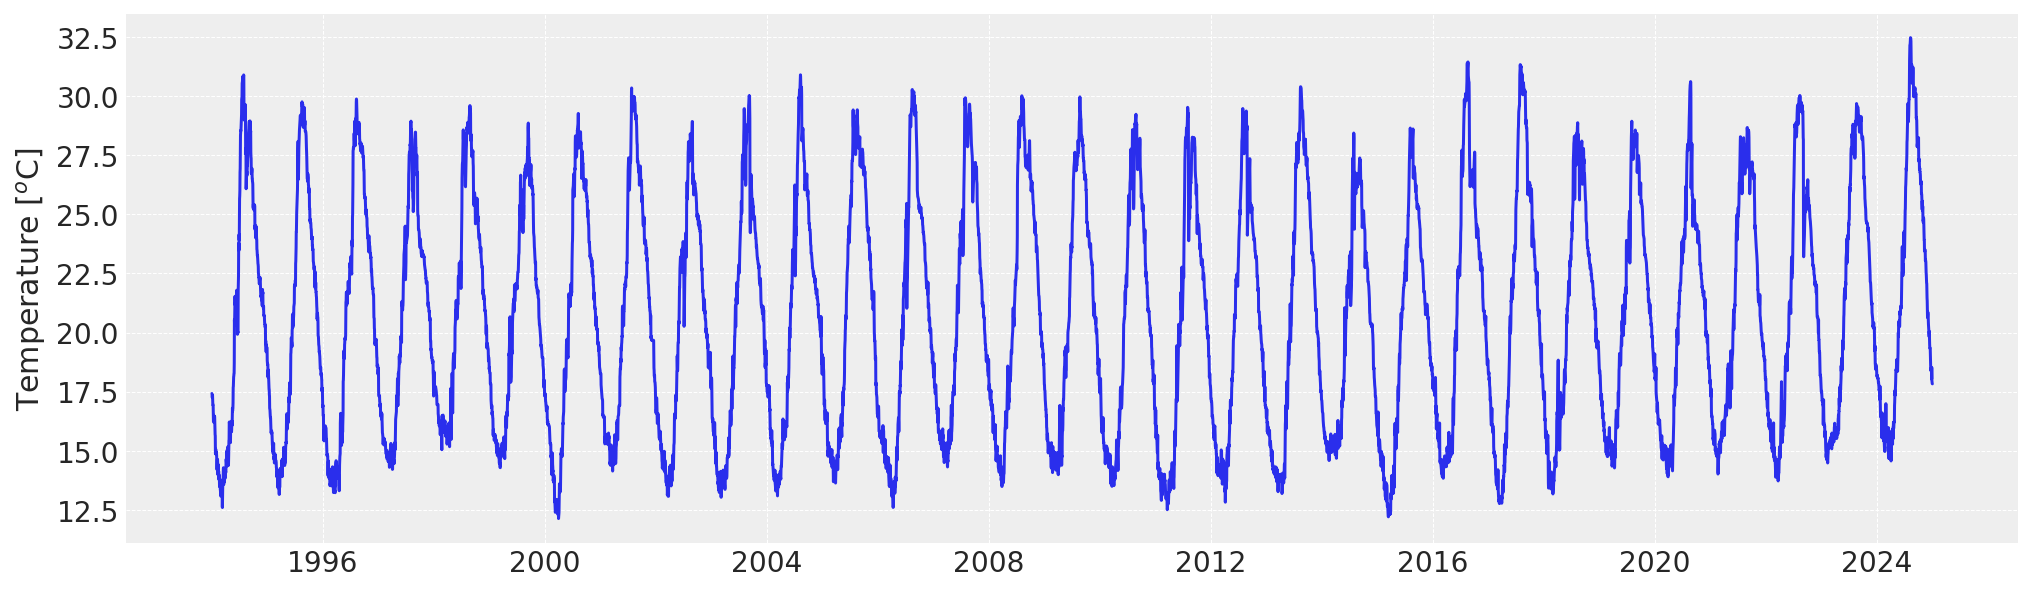

In [16]:
ds_raw_C = ds_raw.sel(time = slice(pd.to_datetime('1994-01-01'),pd.to_datetime('2025-01-01'))).analysed_sst.mean('latitude').mean('longitude') - 273.15
print(f'Length ds_raw_C: {len(ds_raw_C)/365.25}yrs')
time_array_cop = ds_raw_C.time
temp_array_cop = ds_raw_C.values
print(np.floor(np.nanmean(temp_array_cop)))
plt.plot(time_array_cop,temp_array_cop)
plt.ylabel('Temperature [$^{o}$C]')

plt.savefig(f"{output_dir_site}/timeseries_raw.png")
plt.savefig(f"{output_dir_site}/timeseries_raw.pdf")


## create 30 year weekly data for uncertainty analysis

W-SUN
Start date: 1995-01-01 00:00:00
End date: 2025-01-05 00:00:00


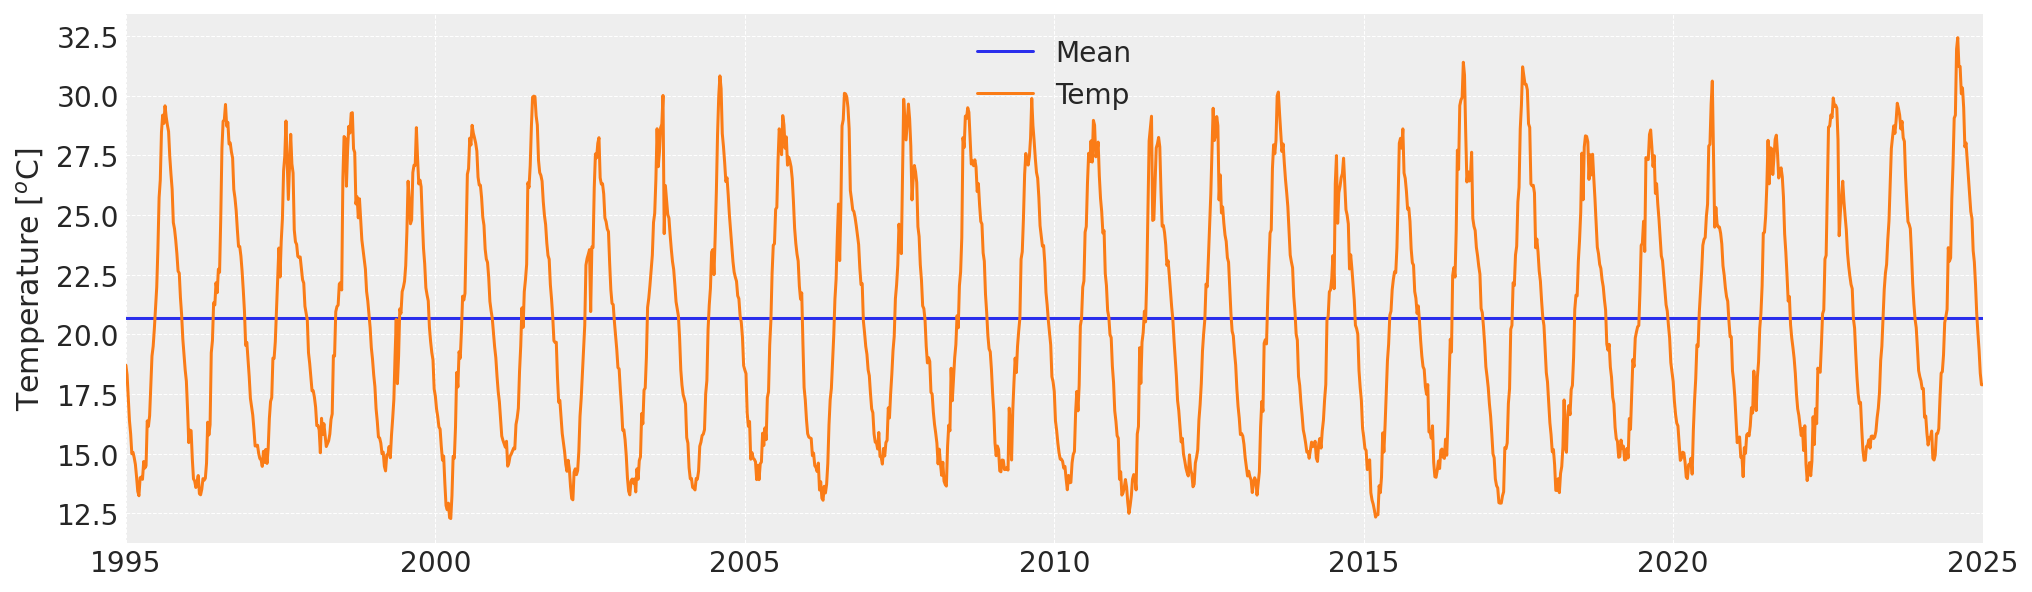

In [17]:
df_C = pd.DataFrame()
df_C['Mean'] = np.zeros(len(temp_array_cop)) + np.nanmean(temp_array_cop)
df_C['Temp'] = temp_array_cop
df_C.index = time_array_cop 
if hemis == 'Northern Hemisphere': 
    df_C = df_C.loc[pd.to_datetime("1995-01-01"):]
    df_w_30 = df_C.resample('W').interpolate('linear').copy()
elif hemis == 'Southern Hemisphere':
    df_C = df_C.loc[pd.to_datetime("1994-07-01"):pd.to_datetime("2024-06-30")]
    df_w_30 = df_C.resample('W').interpolate('linear').copy()

df_w_30.plot()
plt.ylabel('Temperature [$^{o}$C]')

df_w_30.to_csv(f"{output_dir_site}/Weekly_timeseries.csv")

seas_length, freq = get_freq_seaslenght(df_w_30.index)
print(freq)
print(f"Start date: {df_w_30.index[0]}")
print(f"End date: {df_w_30.index[-1]}")

plt.savefig(f"{output_dir_site}/timeseries_{freq}.png")
plt.savefig(f"{output_dir_site}/timeseries_{freq}.pdf")


## Hobday 30yrs Climatology and Threshold

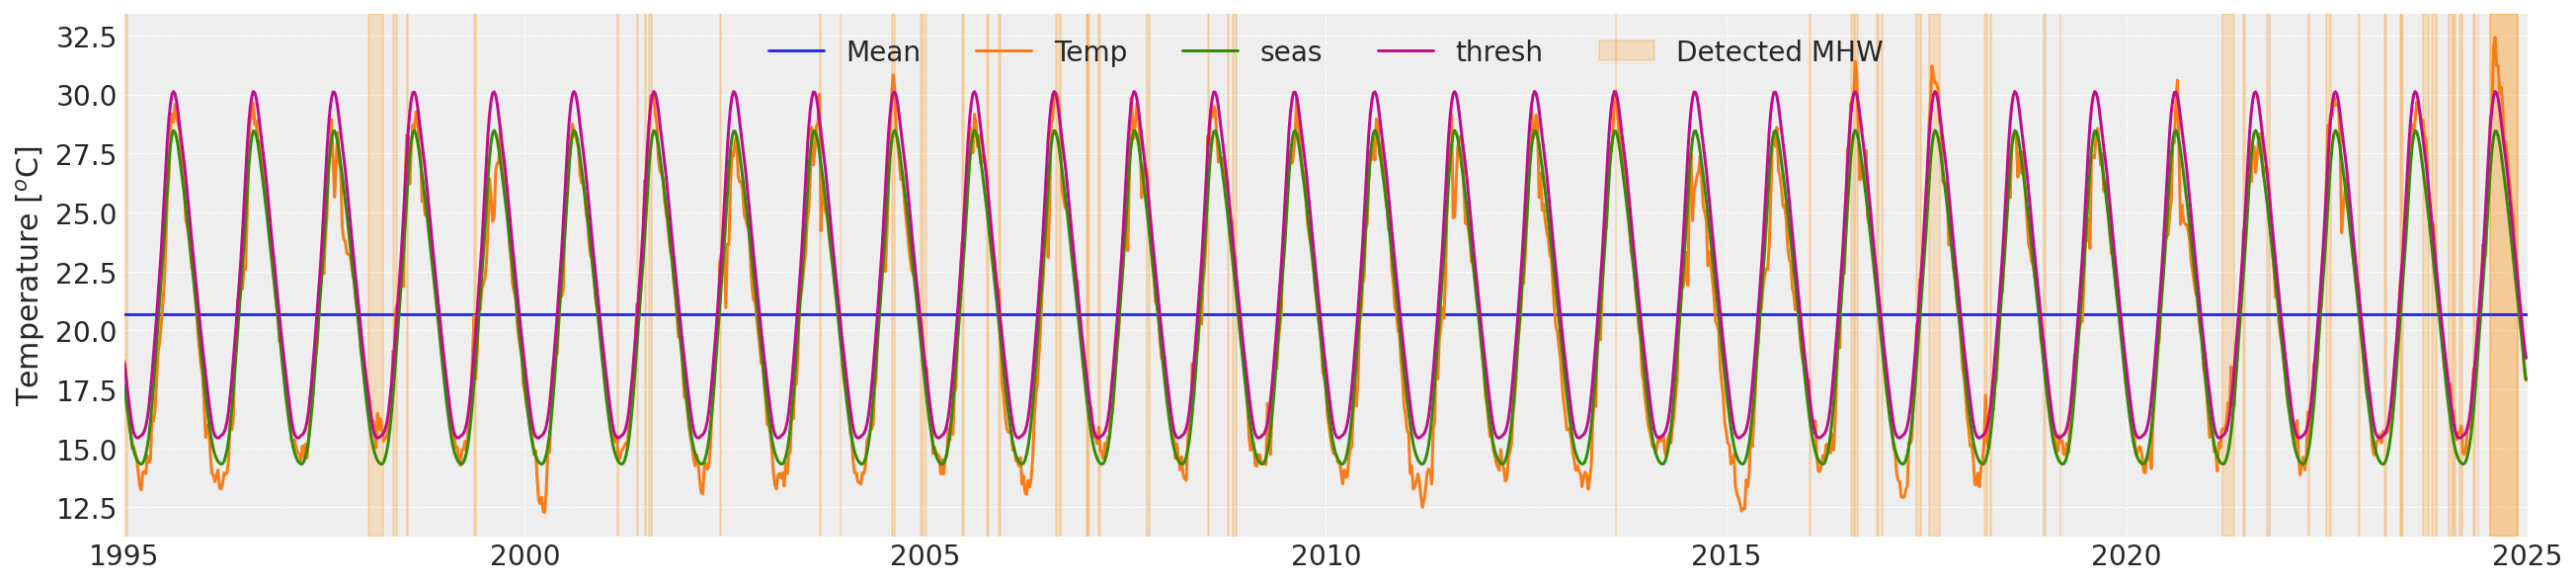

In [18]:
## Calculate Hobday CLimatology and threshold based on 1982-2011 baseline 
df_C_roll =  df_C.rolling(7, min_periods=1, center=True).mean().copy()

mhws_30yrs, clim_30yrs, times_dates_mhw_30yrs  = comparing_to_Hobday(df_C_roll.Temp)

np.save(f"{output_dir_site}/30years_mhw_dict.npy", mhws_30yrs) 

mhw_30yrs_df = pd.DataFrame()
mhw_30yrs_df['seas'] = clim_30yrs['seas']
mhw_30yrs_df['thresh'] = clim_30yrs['thresh']
mhw_30yrs_df.index = pd.to_datetime(times_dates_mhw_30yrs)
mhw_30yrs_df.to_csv(f"{output_dir_site}/Daily_Hobday.csv")


## add weekly adjusted climatology and threshold to weekly data 
df_w_30['seas'] = mhw_30yrs_df['seas'].resample(freq).interpolate('linear')
df_w_30['thresh'] = mhw_30yrs_df['thresh'].resample(freq).interpolate('linear')

fig, ax = plt.subplots(1,1, figsize = (18,4))
df_w_30.plot(ax = ax)
for ds_start,ds_end in zip(mhws_30yrs['date_start'],mhws_30yrs['date_end']):
    ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.2)
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.2, label = 'Detected MHW')
ax.legend(ncols = 5)
ax.set_ylabel('Temperature [$^{o}$C]')

plt.savefig(f"{output_dir_site}/timeseries_with_climThresh_{freq}.png")
plt.savefig(f"{output_dir_site}/timeseries_with_climThresh_{freq}.pdf")

df_w_30.to_csv(f"{output_dir_site}/Weekly_timeseries_withClimThresh.csv")


## Based on Climatology and Threshold suggest right Harmonics Order

Seasonal length: 52


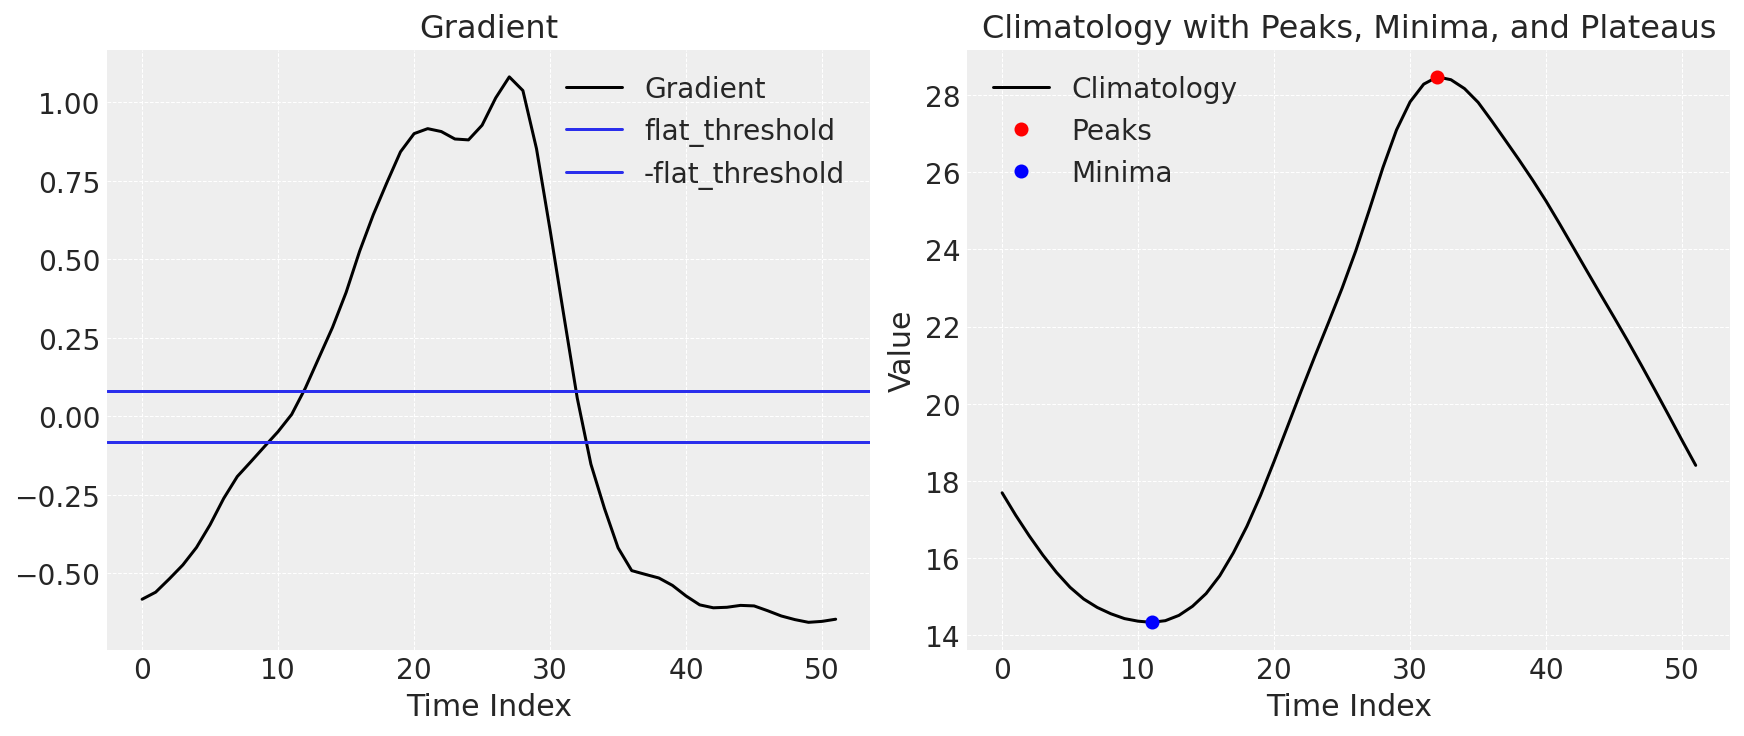

Final suggested harmonics n_order: 1 to 2


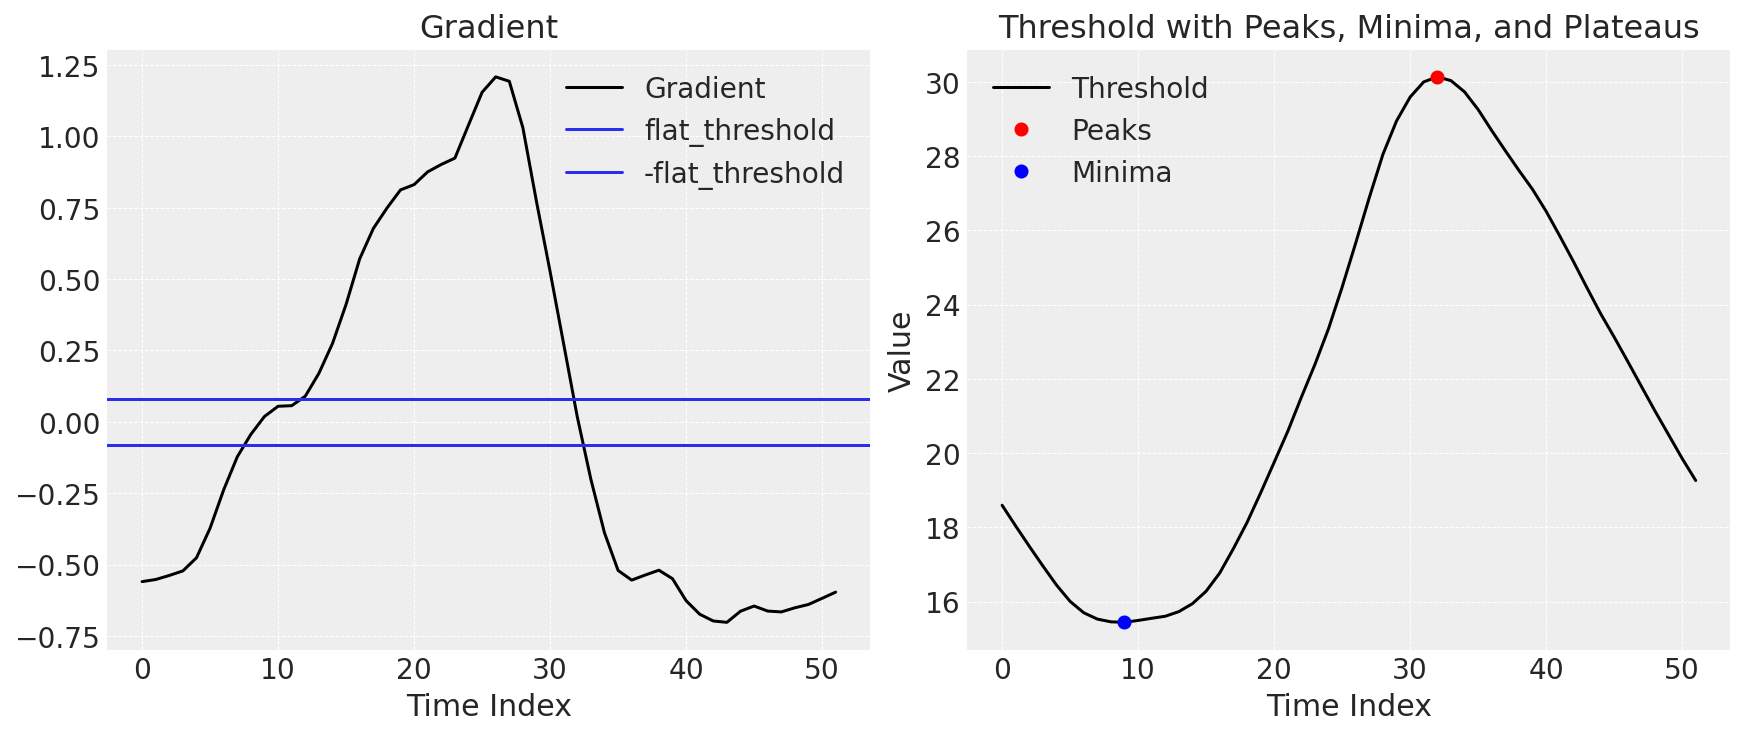

Final suggested harmonics n_order: 1 to 2


In [19]:
seas_length, freq = get_freq_seaslenght(df_w_30.index)
print("Seasonal length:", seas_length)
final_n_order = detect_peaks_minima_plateaus(df_w_30['seas'][:int(seas_length)], var = 'Climatology')
final_n_order2 = detect_peaks_minima_plateaus(df_w_30['thresh'][:int(seas_length)], var = 'Threshold')

# Model Setup

## OG function big with predictions

In [ ]:
def pymc_function(eps_data, n_order = 1, mean_temp = 15):

    ## check timestep first
    ## Check frequency from dataframe 
    seas_length, freq = get_freq_seaslenght(eps_data.index)
    # print("Seasonal length:", seas_length)
    # print("Mean Temperature:", mean_temp)
    
    #### generating fourier features:
    t_data = list(range(len(eps_data)))
    
    periods = np.array(t_data) / seas_length
    ff = pd.DataFrame( { f"{func}_order_{order}": getattr(np, func)(2 * np.pi * periods * order)
            for order in range(1, n_order + 1) for func in ("sin", "cos")})
    ff = ff.to_numpy().T

    ### define model
    with pm.Model() as EPS:
        pass

    ### Add coordinates to model   
    EPS.add_coord("obs_id", t_data)
    EPS.add_coord("fourier_features", np.arange(len(ff)))

    with EPS:
        ## Data containers to enable prediction
        # t = pm.Data ("t", t_data, dims="obs_id")
        y = pm.Data ("y", eps_data.astype(float), dims="obs_id")
        fourier_terms = pm.Data ("fourier_terms", ff)
        
        #### --- a and sigma
        alpha = pm.Normal('alpha', mu=mean_temp, sigma=2 )
        sigma = pm.TruncatedNormal('sigma', mu=1.5, sigma=0.5 , lower=0)


        #### --- seasonality
        beta_fourier = pm.Normal(name="beta_fourier", mu=0, sigma=2, dims="fourier_features")
        seasonality = pm.Deterministic("seasonality", pm.math.dot(beta_fourier, fourier_terms), dims="obs_id")
    
        #### --- mu 
        mu = pm.Deterministic("mu",  alpha + seasonality, dims="obs_id")

        #### --- The Likelihood
        outcome = pm.Normal("likelihood", mu=mu, sigma=sigma, observed=y, dims="obs_id")

        #### --- Sampling
        idata_eps = pm.sample_prior_predictive()
        idata_eps.extend(pm.sample(**sampler_kwargs()))
        idata_eps.extend(pm.sample_posterior_predictive(idata_eps))
    
        
    return idata_eps, EPS

# Uncertainty Analysis

In [21]:
Run_Uncertainty_Analysis = 'No'

## Run Model Diagnostics

In [22]:
# Record the start time
start_time = datetime.now()
print("Start time:", start_time)


# Containers for rolling results
alpha_stds_all = defaultdict(list)
beta_stds_all = defaultdict(list)
seas_stds_all = defaultdict(list)
sigma_stds_all = defaultdict(list)
mu_stds_all = defaultdict(list)
PTR_stds_all = defaultdict(list)
PCR_stds_all = defaultdict(list)
Likelihood_uncertainties_all = defaultdict(list)



# Settings for pymc and data slicing 
n_order = final_n_order # fouerier order
window_sizes = [3, 5 , 7, 10, 15, 20, 25, 30]  #in years
start_date = df_w_30.index[0]   
end_date   = df_w_30.index[-1]
step_years = 1 # integer
mean_temperature = temps_of_interest[Site_Name] #integer

if Run_Uncertainty_Analysis != 'No':
        
    for window_size in window_sizes:
        print(f"\n>>> {window_size}-year windows ({hemis})")
        for wstart, wend, data_slice in generate_time_slices(df_w_30, start_date, end_date, window_size, hemis=hemis):
            print(f"  Window: {wstart.date()} → {wend.date()} ({len(data_slice)} pts)")
            print(f"        : {str(data_slice.index[0])[:10]} to {str(data_slice.index[-1])[:10]}")
    
            # Fit model
            idata_eps_test, model_eps_test = pymc_function(data_slice.Temp, n_order=n_order, mean_temp = mean_temperature)
          
            # Get uncertainties
            result = summarize_uncertainty_eps(idata_eps_test,  data_slice.index)
    
            ## saving results
            alpha_stds_all[window_size].append(result["alpha_std"])
            seas_stds_all[window_size].append(result["seasonality_std"])
            beta_stds_all[window_size].append(result["beta_std"])
            sigma_stds_all[window_size].append(result["sigma_std"])
            mu_stds_all[window_size].append(result["mu_std"])
            PTR_stds_all[window_size].append(result["PTR_std"])    
            PCR_stds_all[window_size].append(result["PCR_std"])
            Likelihood_uncertainties_all[window_size].append(result["likelihood_std"])
    
     
# Record the end time
end_time = datetime.now()
print("Start time:", start_time)
print("End time:", end_time)

# Calculate and print the duration
duration = end_time - start_time
print("Total run time:", duration)

Start time: 2026-01-29 12:57:47.522405
Start time: 2026-01-29 12:57:47.522405
End time: 2026-01-29 12:57:47.523405
Total run time: 0:00:00.001000


### Save Model Output 

In [23]:
if Run_Uncertainty_Analysis != 'No':

    # Your rolling-window results
    variables_dict_eps = {
        "Alpha Uncertainy": alpha_stds_all,
        "Beta Uncertainty": beta_stds_all,
        "Seasonality Uncertainty": seas_stds_all,
        "Sigma Uncertainty": sigma_stds_all,
        "Mu Uncertainty": mu_stds_all,
         "PCR Uncertainty": PCR_stds_all,
        "PTR Uncertainty": PTR_stds_all,
        "Likelihood Uncertainty": Likelihood_uncertainties_all,
    }
    
    
    
    # Save dictionary
    with open(os.path.join(output_dir_site, "uncertainty_metrics.pkl"), "wb") as f:
        pickle.dump(variables_dict_eps, f)

else:
# to load later
    with open(f"{output_dir_site}/uncertainty_metrics.pkl", "rb") as f:
        variables_dict_eps = pickle.load(f)    

### Save Model Graph

In [24]:
if Run_Uncertainty_Analysis != 'No':
    # Generate the pymc graph
    graph = pm.model_to_graphviz(model_eps_test)
    # Save it to the output_dir_site
    graph.render(filename=os.path.join(output_dir_site, "pymc_model_eps_graphic"), format="png", cleanup=True)
    
   

## Plot Model Diagnostics

In [25]:
Run_Uncertainty_Analysis = 'Yes'

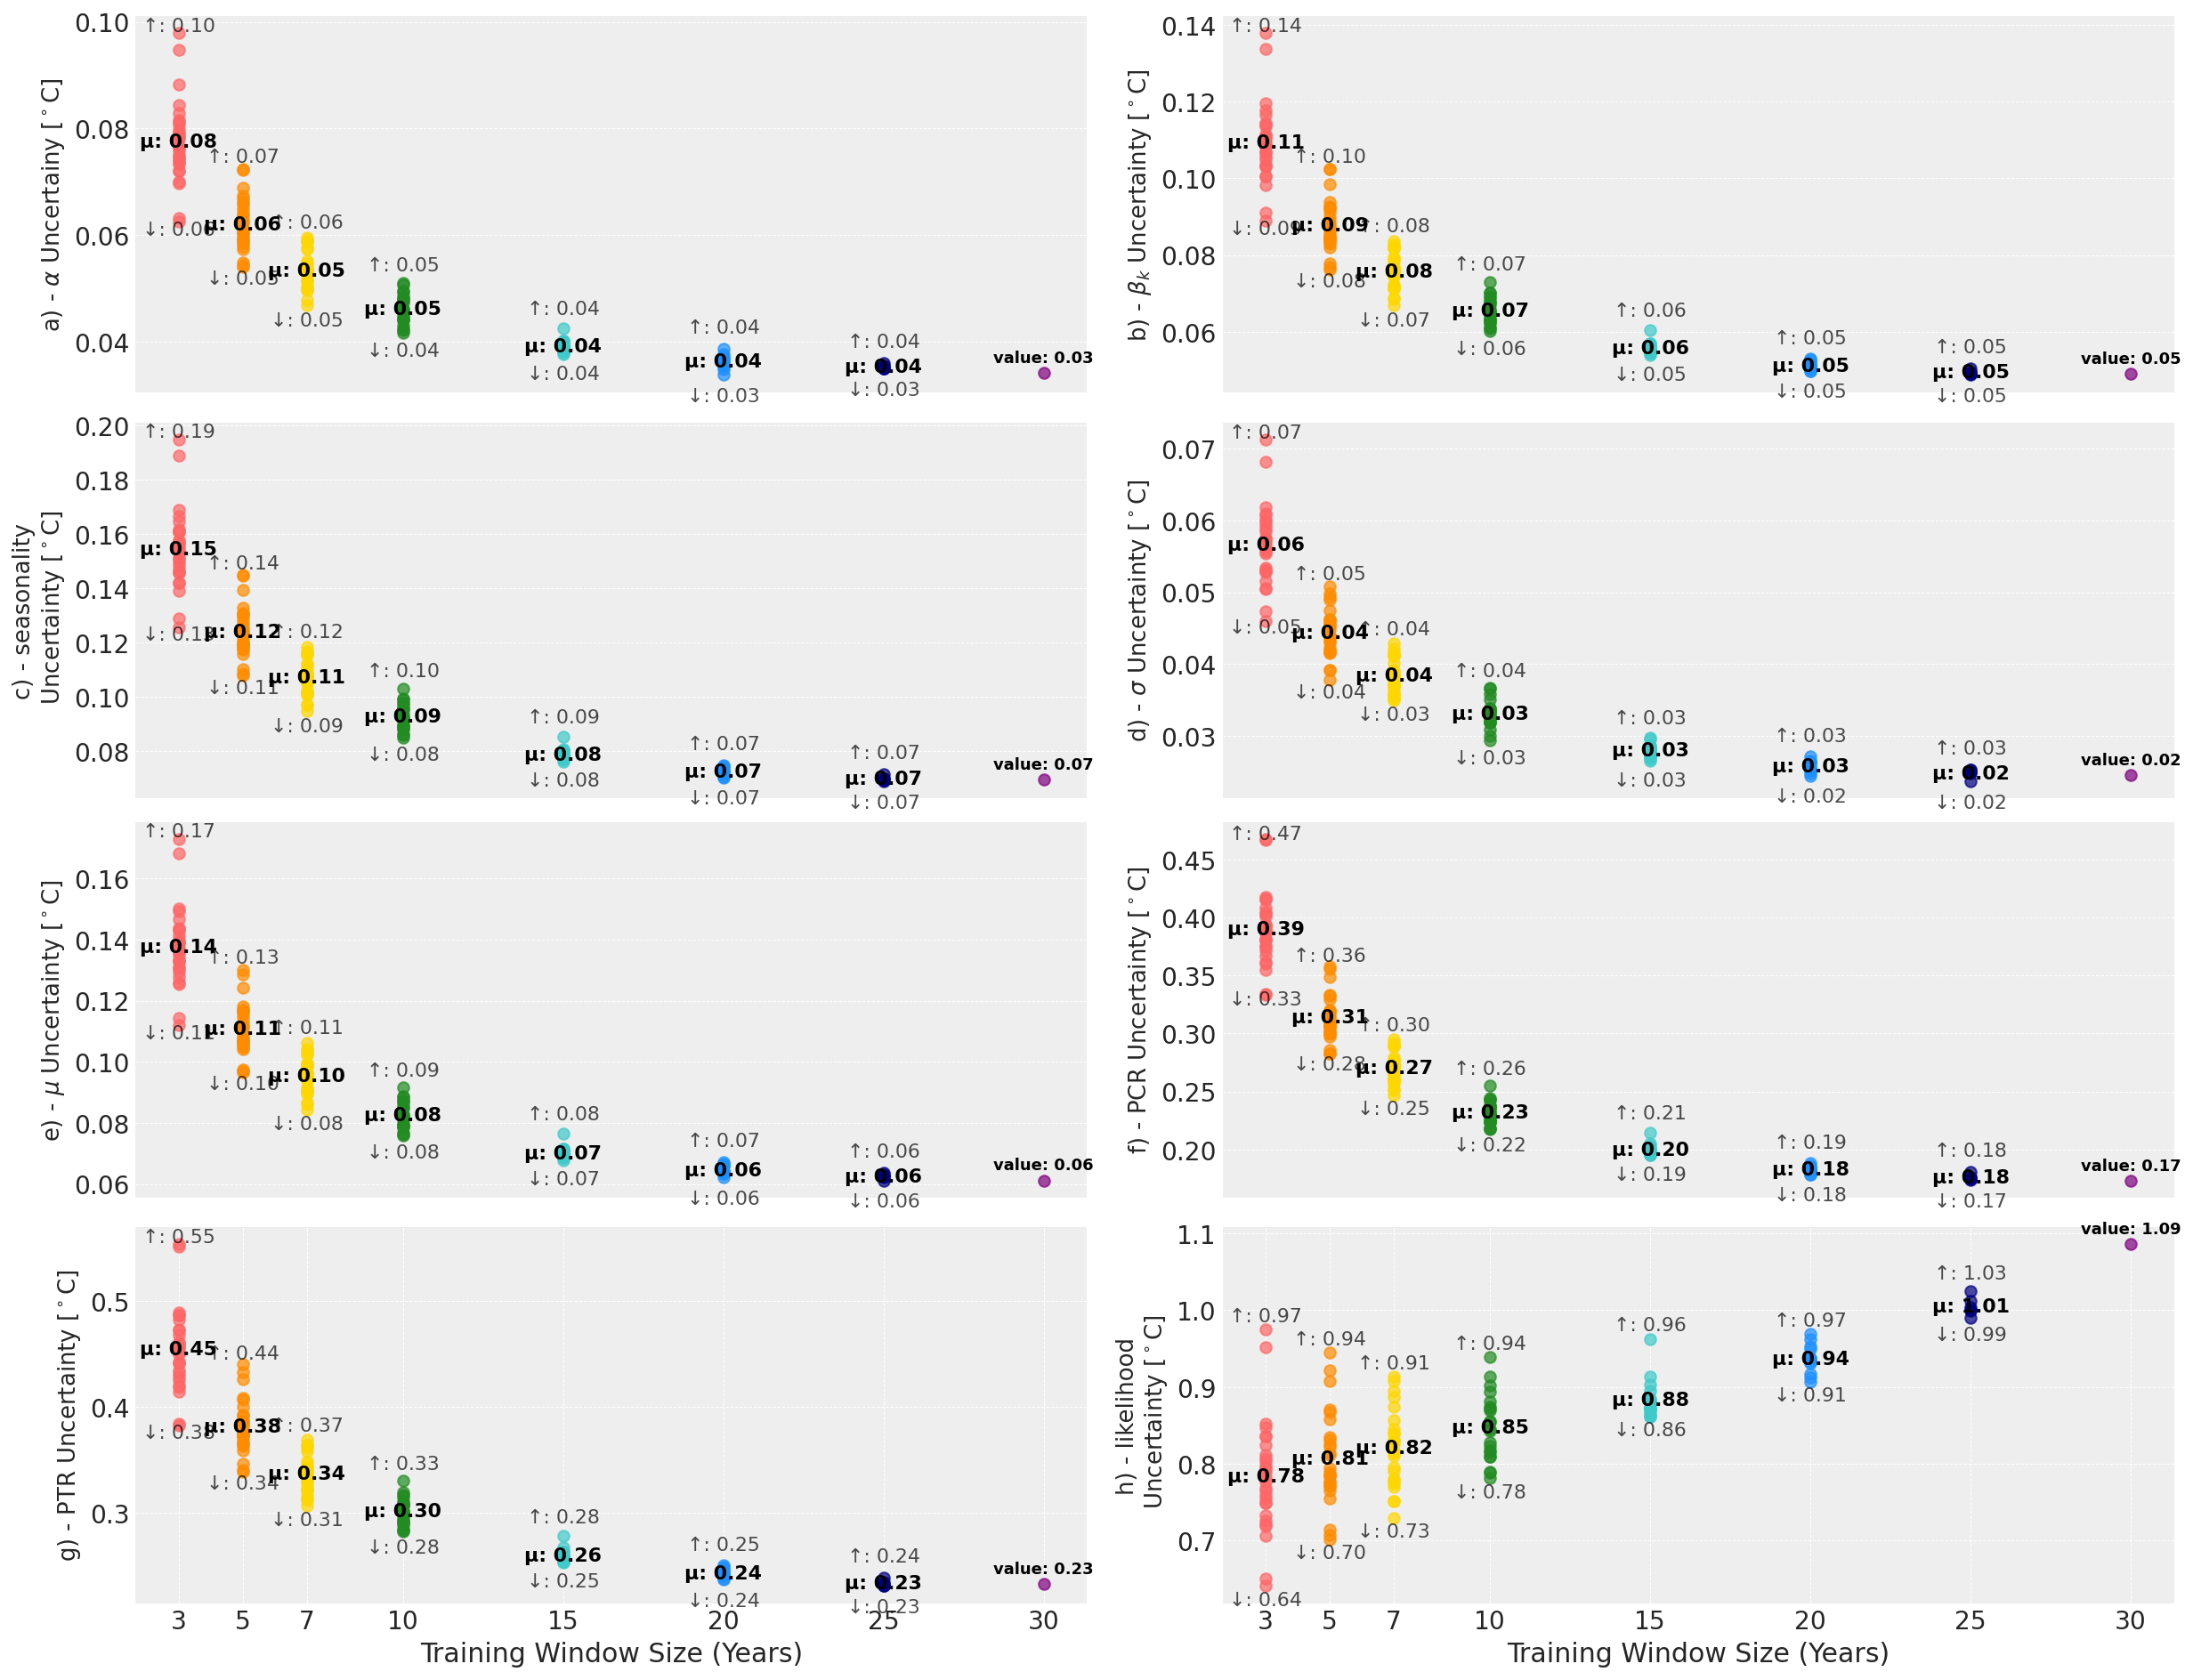

In [26]:
greek_map = {
    "Alpha": r"$\alpha$",
    "Beta": r"$\beta_k$",
    "Mu": r"$\mu$",
    "Sigma": r"$\sigma$",
    "Likelihood": 'likelihood\n',
    "Seasonality": 'seasonality\n'
}


if Run_Uncertainty_Analysis != 'No':

    # get rainbow colors for plotting
    n = len(window_sizes)  # number of colors needed
    box_colors = get_custom_soft_rainbow(n)
    
    
    
    # Prepare subplots
    # Subplot layout
    n_vars = len(variables_dict_eps.items())
    n_cols = 2
    n_rows = (n_vars + 1) // n_cols
    
    
    
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(17, 13), constrained_layout=True)#, sharex= 'col')
    axs = axs.flatten()
    
    window_labels = [f"{w}y" for w in window_sizes]
    
    # Loop over variables
    for i, (var_name, data_dict) in enumerate(variables_dict_eps.items()):
        ax = axs[i]
      
    
        # Scatter points for each window
        ww = 0
        for window_size in window_sizes:
            x = [window_size] * len(data_dict[window_size])
    
            
            y = data_dict[window_size]
            ax.scatter(x, y, alpha=0.7, s=40, label=f"{window_size}y", color = box_colors[ww])
    
            # Add min, max, mean text for each window size
            y_min = np.min(y)
            y_max = np.max(y)
            y_mean = np.mean(y)
    
            xpos = window_size 
            
            # Add vertical spacing offsets for labels
            offset = (ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.08  # 2% of y-range
            
            # Adjust vertical positions a bit to avoid overlap
            if len(y) == 1:  # Only one value, so just print that single value
                val = y[0]
                ax.text(xpos, val+ offset/2, f"value: {val:.2f}", ha='center', va='center', fontsize=9, fontweight='bold', color='black')
            else:
                ax.text(xpos, y_min- offset, f"↓: {y_min:.2f}", ha='center', va='bottom', fontsize=11, color='black', alpha=0.7)
                ax.text(xpos, y_max+ offset, f"↑: {y_max:.2f}", ha='center', va='top', fontsize=11, color='black', alpha=0.7)
                ax.text(xpos, y_mean, f"μ: {y_mean:.2f}", ha='center', va='center', fontsize=11, fontweight='bold', color='black')
    
    
            
            ww +=1
        
        # Trend line
        all_x = []
        all_y = []
        for window_size in window_sizes:
            all_x.extend([window_size] * len(data_dict[window_size]))
            all_y.extend(data_dict[window_size])
      
        if i >= n_vars-2:
            ax.set_xlabel("Training Window Size (Years)")
            ax.set_xticks(np.array(window_sizes))
        else:
            ax.set_xlabel("")
            ax.set_xticks([])

        # Replace words with Greek symbols if present
        for k, v in greek_map.items():
            var_name = var_name.replace(k, v)
            
        ax.set_ylabel(f"{string.ascii_lowercase[i]}) - {var_name} [$^\\circ$C]", fontsize = 13)
        ax.grid(True)
     
    
        
    # If fewer variables than subplots, remove extras
    for j in range(i + 1, len(axs)):
        fig.delaxes(axs[j])

    
    
    # Save the whole figure
    plt.savefig(os.path.join(output_dir_site, "uncertainty_metrics_grid_no_decline_noweight_testtesttest.png"), dpi=300)
    plt.savefig(os.path.join(output_dir_site, "uncertainty_metrics_grid_no_decline_noweight_testtesttest.pdf"), dpi=300)
    
    plt.show()





### Calculating similarty between cliamte years (1. July - 30.June the next year) 

In [27]:
if Run_Uncertainty_Analysis != 'No':

    similarity_scores_eps = []
    
    
    
    for window_size in window_sizes:
        # print(f"\n>>> {window_size}-year windows ({hemis})")
        for i, (wstart, wend, data_slice) in enumerate(generate_time_slices(df_w_30, start_date, end_date, window_size, hemis=hemis)):
            # print(f"  Window: {wstart.date()} → {wend.date()} ({len(data_slice)} pts)")
            # print(f"        : {str(data_slice.index[0])[:10]} to {str(data_slice.index[-1])[:10]}")
    
            sim_score = climate_yearwise_dtw_similarity(data_slice.Temp, window_size, i)
            similarity_scores_eps.append({
                "window_size": window_size,
                "start_idx": wstart,
                "start_date": data_slice.index[0],
                "end_date": data_slice.index[-1],
                "similarity": sim_score,
            })
    
       
    
    
    # Flatten the variables_dict_eps into a long dataframe
    records = []
    for var_name, std_lists in variables_dict_eps.items():
        for (window_size, std_values) in std_lists.items():
            for i, std_val in enumerate(std_values):
                records.append({
                    "variable": var_name,
                    "window_size": window_size,  # convert months to years
                    "run_index": i,
                    "std_value": std_val
                })
    
    df_std = pd.DataFrame(records)
    
    
    
    # Your similarity score list from earlier
    # Each record has: window_size (in months), start_idx, similarity
    df_sim = pd.DataFrame(similarity_scores_eps)
    df_sim["window_size"] = df_sim["window_size"]  # convert to years
    df_sim["run_index"] = df_sim.groupby("window_size").cumcount()  # to match loop index
    
    
    df_plot_eps = pd.merge(df_std, df_sim, on=["window_size", "run_index"])

Total Number of Time Windows: 28
Total Number of Time Windows: 26
Total Number of Time Windows: 24
Total Number of Time Windows: 21
Total Number of Time Windows: 16
Total Number of Time Windows: 11
Total Number of Time Windows: 6
Total Number of Time Windows: 1


### Plot DTW similarity vs Model Diagnostic

In [28]:
from matplotlib.colors import LinearSegmentedColormap

colors = [
    (0.0, "blue"),    # start: dark blue
    (0.25, "cornflowerblue"),
    (0.5, "green"),   # middle: green
    (0.75, "gold"),      # end: red/orange
     (1., "red")]
    

# Create colormap
custom_cmap = LinearSegmentedColormap.from_list("BlueGreenRed", colors)

# Example: visualize the colormap with a gradient
gradient = np.linspace(0, 1, 190).reshape(1, -1)


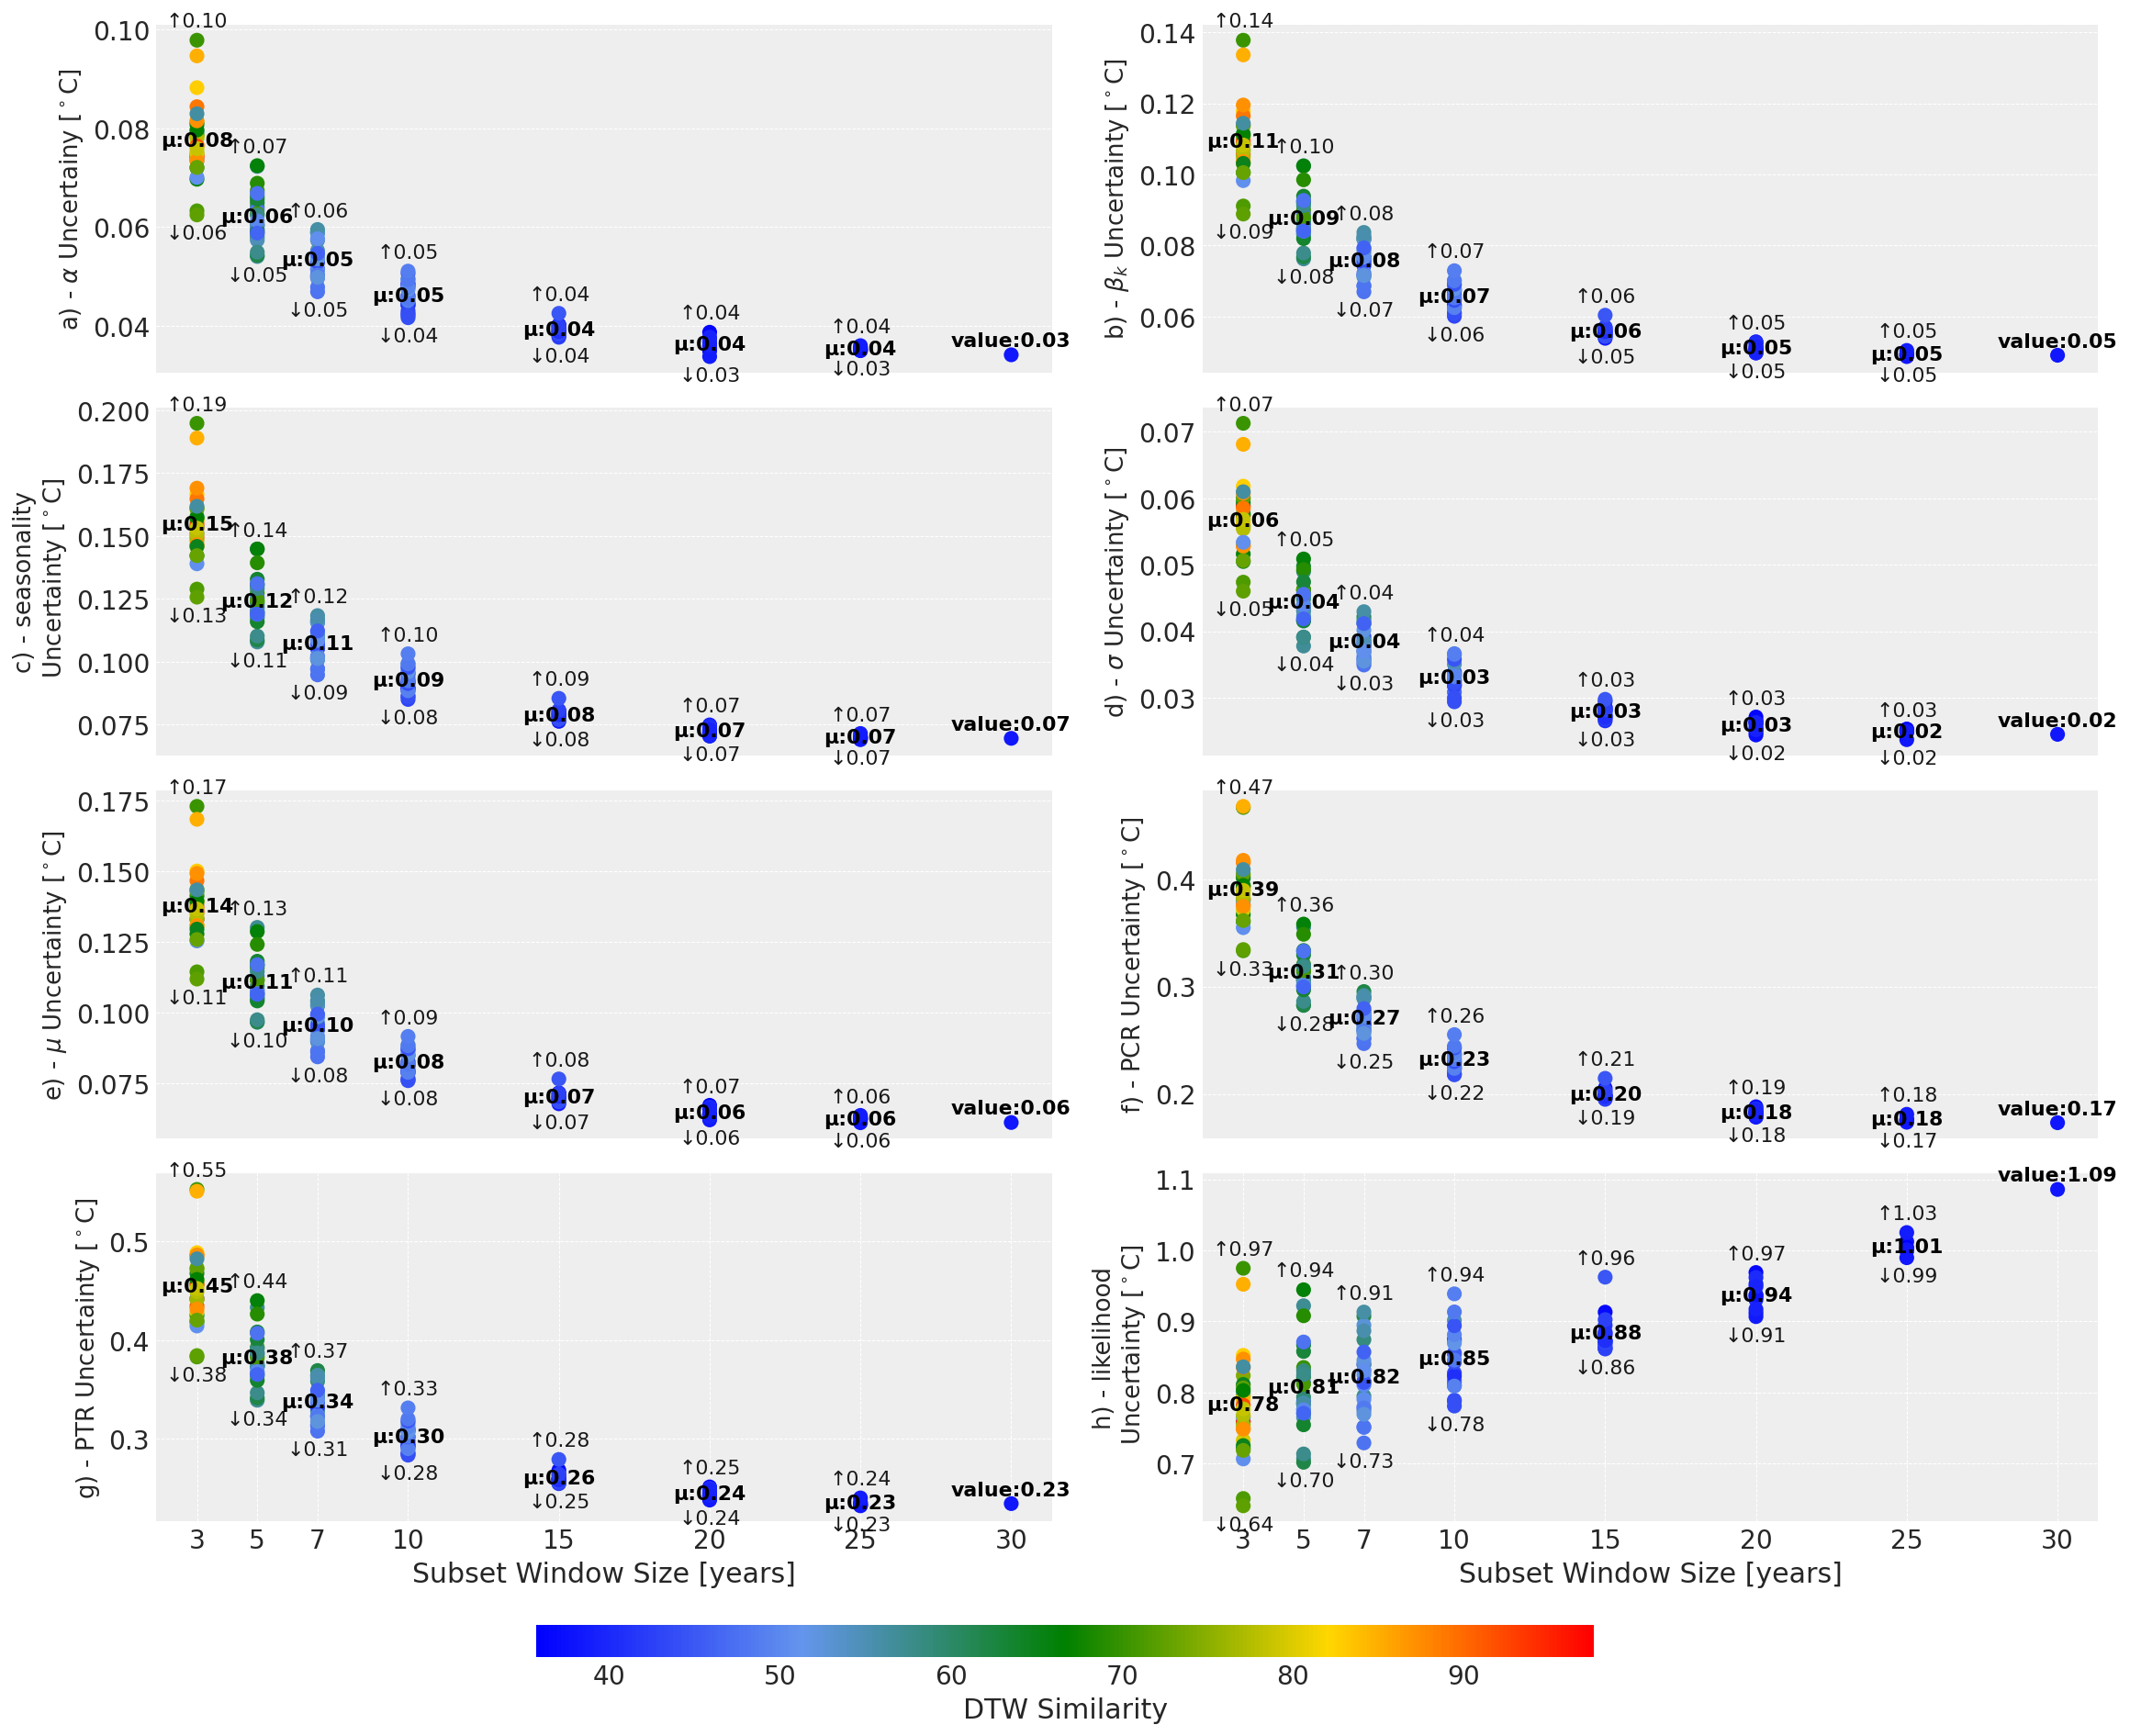

In [29]:
# Mapping from text to Greek symbols


if Run_Uncertainty_Analysis != 'No':
    vmin = df_plot_eps["similarity"].min()
    vmax = df_plot_eps["similarity"].max()
    
    variables = df_plot_eps["variable"].unique()
    n_vars = len(variables)
    
    n_vars = len(variables_dict_eps.items())
    n_cols = 2
    n_rows = (n_vars + 1) // n_cols
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(16, 12), constrained_layout=True)#, sharex= True)
    axs = axs.flatten()
    
    for i, (var,data_dict) in enumerate(variables_dict_eps.items()): 
        ax = axs[i]
        data = df_plot_eps[df_plot_eps["variable"] == var]
    
        scatter = ax.scatter(data["window_size"], data["std_value"], c=data["similarity"], cmap=custom_cmap , #"plasma",  # or "plasma", "coolwarm", etc.
                             s=50,alpha=1,vmin=vmin,vmax=vmax )
        
        if i >= n_vars-2:
            ax.set_xlabel("Subset Window Size [years]")
            ax.set_xticks(np.array(window_sizes))
        else:
            ax.set_xlabel("")
            ax.set_xticks([])

        # Replace words with Greek symbols if present
        for k, v in greek_map.items():
            var = var.replace(k, v)
            
            
        ax.set_ylabel(f"{string.ascii_lowercase[i]}) - {var} [$^\\circ$C]", fontsize = 13)
        ax.grid(True)

        # Add min, max, mean text for each window size

        for window_size in window_sizes:
            x = [window_size] * len(data_dict[window_size])
            y = data_dict[window_size]
            
            y_min = np.min(y)
            y_max = np.max(y)
            y_mean = np.mean(y)
    
            xpos = window_size 
            
            # Add vertical spacing offsets for labels
            offset = (ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.08  # 2% of y-range
            
            # # Adjust vertical positions a bit to avoid overlap
            if len(y) == 1:  # Only one value, so just print that single value
                val = y[0]
                ax.text(xpos, val+ offset/2, f"value:{val:.2f}", ha='center', va='center', fontsize=11, fontweight='bold', color='black')
            else:
                
                ax.text(xpos, y_min- offset, f"↓{y_min:.2f}", ha='center', va='bottom', fontsize=11, color='black', alpha=0.9)
                ax.text(xpos, y_max+ offset, f"↑{y_max:.2f}", ha='center', va='top', fontsize=11, color='black', alpha=0.9)
                ax.text(xpos, y_mean, f"μ:{y_mean:.2f}", ha='center', va='center', fontsize=11, fontweight='bold', color='black')
            # yerr = [[y_mean - y_min], [y_max - y_mean]]
            # ax.errorbar(window_size, y_mean, yerr=yerr, fmt='o', color='black', capsize=4)
    
    
            
    
    # # Add colorbar to the last axis
    # cbar = fig.colorbar(scatter, ax=axs[i], orientation="vertical")
    # cbar.set_label("DTW Similarity")
    
    # Optional: remove unused axes
    for j in range(i + 1, len(axs)):
        last_ax = axs[j]
        fig.delaxes(last_ax)
    
        # Get the position (bounding box) of the last subplot
        pos = last_ax.get_position()
    
    # Shrink it down to make a smaller colorbar inside that space
    # e.g., 60% width, centered
    cax = fig.add_axes([ 0.25, -0.04,0.5,0.02
        # pos.x0 + 0.05   ,
        # pos.y0 + 0.15*pos.height, # bottom
        # pos.width,            # width
        # 0.25*pos.height            # height
    ])
    
    # Add the colorbar to this custom axis
    cbar = fig.colorbar(scatter, cax=cax, orientation="horizontal")
    cbar.set_label("DTW Similarity")


    
    plt.savefig(os.path.join(output_dir_site, "Figure_06.png"), dpi=300, bbox_inches="tight")
    plt.savefig(os.path.join(output_dir_site, "Figure_06.pdf"), dpi=300, bbox_inches="tight")
    
    plt.show()

# Daily Model Run

## Preparing subsets around doi

For Site Japan, all Files and Figures will be saved in:
C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection/Figures/Japan
Northern Hemisphere
Length ds_raw_C: 31.000684462696782yrs
W-SUN
Start date: 1995-01-01 00:00:00
End date: 2025-01-05 00:00:00
[WARN] 'centered' window beyond data end → shifting to series end
[WARN] 'centered' window beyond data end → shifting to series end
[WARN] 'centered' window beyond data end → shifting to series end
[WARN] 'centered' window beyond data end → shifting to series end
[WARN] 'centered' window beyond data end → shifting to series end
    site  subset_years  start_date    end_date  mean_temp  anomaly_vs_full  \
0  Japan             3  2022-01-01  2024-12-31      21.52             0.85   
1  Japan             5  2020-01-01  2024-12-31      21.21             0.54   
2  Japan             7  2018-01-01  2024-12-31      21.07             0.41   
3  Japan            12  2012-12-31  2024-12-31      20.80       

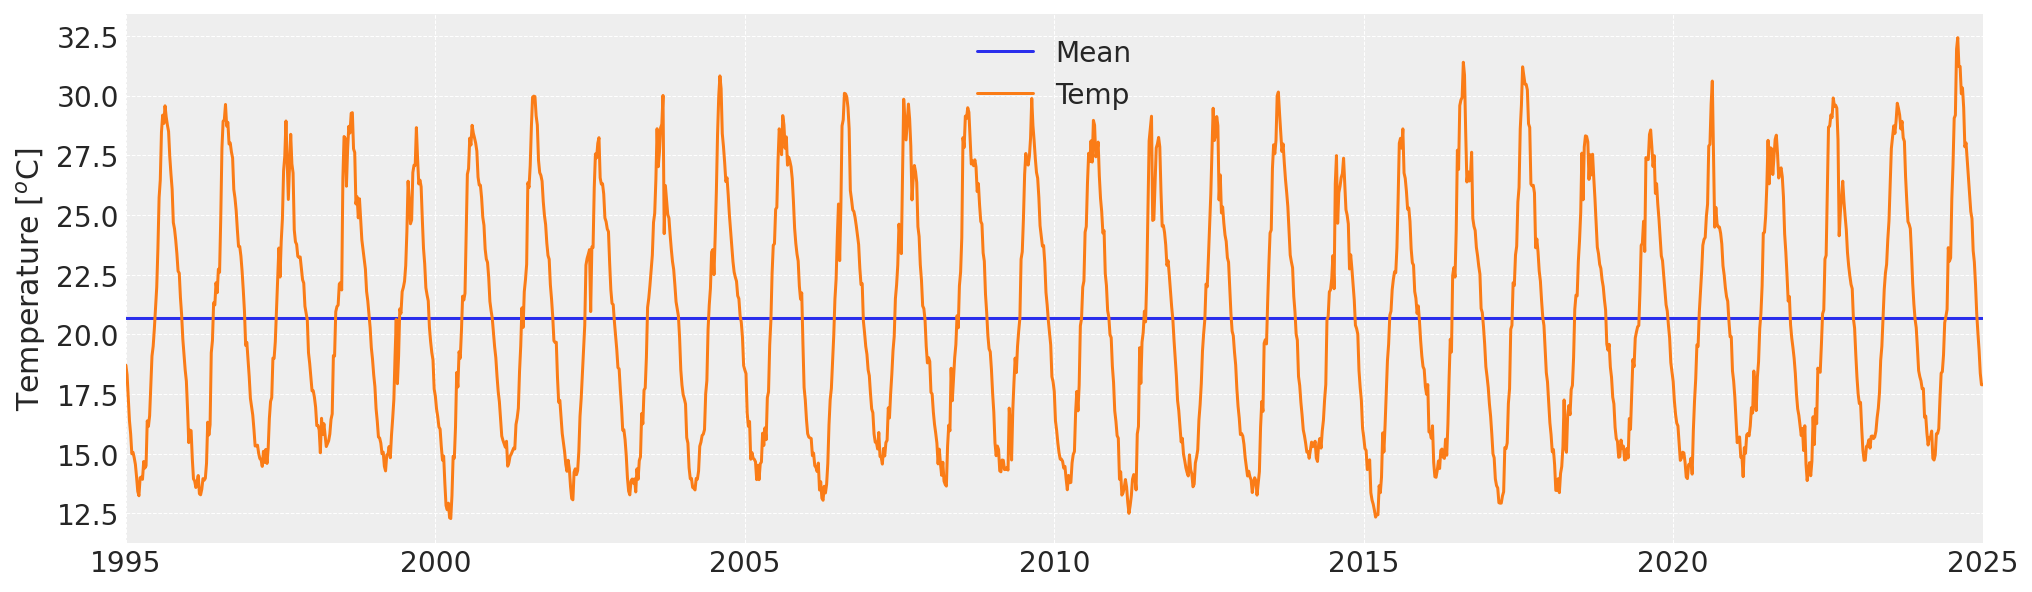

In [30]:
##### testing contectualising 


## these are the names of the 4 different stations and the date of interests (MHW events) 
date_of_interest = {
    "Japan": "2024-08-01",
    "NorthWestShelf": "2004-12-15",
    "SouthWA": "2011-03-01",
    "UK": "2013-07-30",
}

temps_of_interest = {
    "Japan": 20,
    "NorthWestShelf": 25,
    "SouthWA": 20,
    "UK": 10,
}

# Your file
file_path = f"{file_folder}/data/Japan.nc"

# Open datasetJapan
ds_raw = xr.open_dataset(file_path)

# Extract site name from file name (without extension)
Site_Name = os.path.splitext(os.path.basename(file_path))[0]



output_dir_site = figures_folder + r'/' + Site_Name
os.makedirs( output_dir_site, exist_ok=True)
print(f"For Site {Site_Name}, all Files and Figures will be saved in:\n{output_dir_site}")

hemis = get_hemisphere(ds_raw.latitude.values.mean())
print(hemis)
ds_raw_C = ds_raw.sel(time = slice(pd.to_datetime('1994-01-01'),pd.to_datetime('2025-01-01'))).analysed_sst.mean('latitude').mean('longitude') - 273.15
print(f'Length ds_raw_C: {len(ds_raw_C)/365.25}yrs')
time_array_cop = ds_raw_C.time
temp_array_cop = ds_raw_C.values

df_C = pd.DataFrame()
df_C['Mean'] = np.zeros(len(temp_array_cop)) + np.nanmean(temp_array_cop)
df_C['Temp'] = temp_array_cop
df_C.index = time_array_cop 
if hemis == 'Northern Hemisphere': 
    df_C = df_C.loc[pd.to_datetime("1995-01-01"):]
    df_w_30 = df_C.resample('W').interpolate('linear').copy()
elif hemis == 'Southern Hemisphere':
    df_C = df_C.loc[pd.to_datetime("1994-07-01"):pd.to_datetime("2024-06-30")]
    df_w_30 = df_C.resample('W').interpolate('linear').copy()

df_w_30.plot()
plt.ylabel('Temperature [$^{o}$C]')

df_w_30.to_csv(f"{output_dir_site}/Weekly_timeseries.csv")

seas_length, freq = get_freq_seaslenght(df_w_30.index)
print(freq)
print(f"Start date: {df_w_30.index[0]}")
print(f"End date: {df_w_30.index[-1]}")


## Calculate Hobday CLimatology and threshold based on 1982-2011 baseline 
df_C_roll =  df_C.rolling(7, min_periods=1, center=True).mean().copy()






import pandas as pd

def summarize_subset(df, years):
    """Return a dict summarising the subset period and SST context."""
    
    start = df.index.min()
    end   = df.index.max()
    meanT = df.Temp.mean()
    
    # Simple interpretation rule (you can refine later)
    long_mean = df_C_roll.Temp.mean()
    anomaly = meanT - long_mean
    
    if anomaly > 0.2:
        comment = "warmer-than-average period"
    elif anomaly < -0.2:
        comment = "cooler-than-average period"
    else:
        comment = "near-average period"
        
    return {
        "subset_years": years,
        "start_date": start.date(),
        "end_date": end.date(),
        "mean_temp": round(meanT, 2),
        "anomaly_vs_full": round(anomaly, 2),
        "comment": comment
    }


# Define selected center date
selected_date = pd.to_datetime(date_of_interest[Site_Name]) #pd.to_datetime("2013-06-01")

# Make sure index is datetime
df_C_roll = df_C_roll.copy()
df_C_roll.index = pd.to_datetime(df_C_roll.index)


# Build your datasets
df_C_roll03 = make_subset(df_C_roll, selected_date, years=3, mode="centered", plot=False)
df_C_roll05 = make_subset(df_C_roll, selected_date, years=5, mode="centered", plot=False)
df_C_roll07 = make_subset(df_C_roll, selected_date, years=7, mode="centered", plot=False)
df_C_roll12 = make_subset(df_C_roll, selected_date, years=12, mode="centered", plot=False)
df_C_roll30 = make_subset(df_C_roll, selected_date, years=30, mode="centered", plot=False)



# Build summary table for this site
summary_rows = []

summary_rows.append(summarize_subset(df_C_roll03, 3))
summary_rows.append(summarize_subset(df_C_roll05, 5))
summary_rows.append(summarize_subset(df_C_roll07, 7))
summary_rows.append(summarize_subset(df_C_roll12, 12))
summary_rows.append(summarize_subset(df_C_roll30, 30))

summary_df = pd.DataFrame(summary_rows)
summary_df["site"] = Site_Name
summary_df = summary_df[["site", "subset_years", "start_date", "end_date", 
                         "mean_temp", "anomaly_vs_full", "comment"]]

# Save table
summary_df.to_csv(f"{output_dir_site}/subset_context_table.csv", index=False)
print(summary_df)

# Convert to LaTeX table
latex_table = summary_df.to_latex(
    index=False,
    float_format="%.2f",
    column_format="l c c c c c l",
    escape=False
)

print(latex_table)

# Save to a .tex file
with open(f"{output_dir_site}/subset_context_table.tex", "w") as f:
    f.write(latex_table)
    


In [31]:
# Define selected center date
selected_date = pd.to_datetime(date_of_interest[Site_Name]) #pd.to_datetime("2013-06-01")

# Make sure index is datetime
df_C_roll = df_C_roll.copy()
df_C_roll.index = pd.to_datetime(df_C_roll.index)


# Build your datasets
df_C_roll03 = make_subset(df_C_roll, selected_date, years=3, mode="centered", plot=False)
df_C_roll05 = make_subset(df_C_roll, selected_date, years=5, mode="centered", plot=False)
df_C_roll07 = make_subset(df_C_roll, selected_date, years=7, mode="centered", plot=False)
df_C_roll12 = make_subset(df_C_roll, selected_date, years=12, mode="centered", plot=False)
df_C_roll30 = make_subset(df_C_roll, selected_date, years=30, mode="centered", plot=False)


## settings for later plotting
titles = ['30yrs','12yrs', '7yrs','5yrs','3yrs']
years = [30,12,7,5,3]



[WARN] 'centered' window beyond data end → shifting to series end
[WARN] 'centered' window beyond data end → shifting to series end
[WARN] 'centered' window beyond data end → shifting to series end
[WARN] 'centered' window beyond data end → shifting to series end
[WARN] 'centered' window beyond data end → shifting to series end


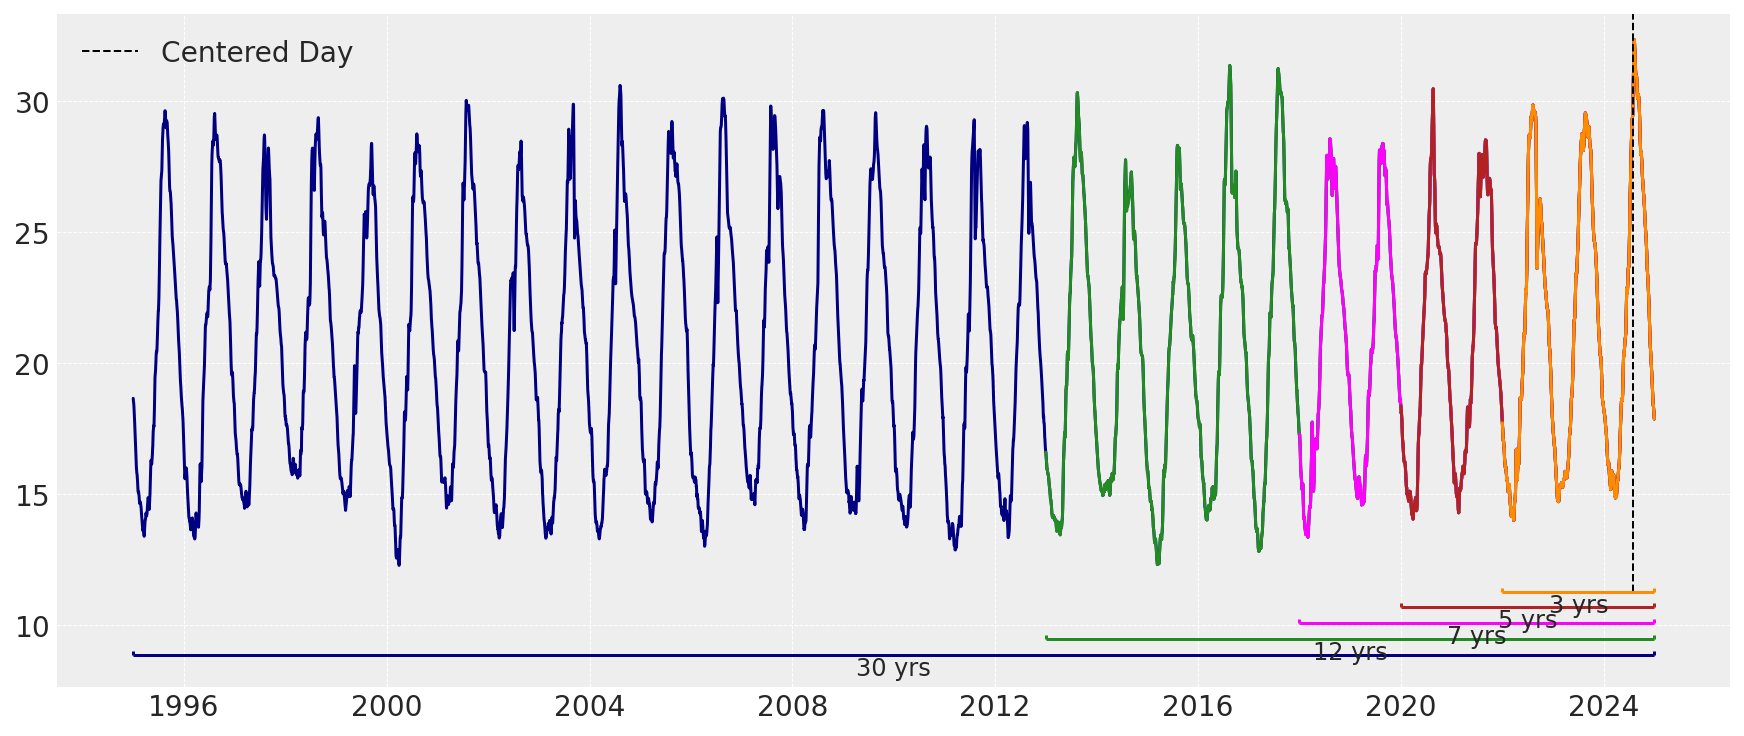

In [32]:
def draw_bracket(ax, xspan, y, text=None, color="black", lw=1.5, text_offset=0.05):
    """
    Draw a horizontal bracket under a datetime x-axis span.
    """
    x0, x1 = xspan
    ax.hlines(y, x0, x1, colors=color, lw=lw)  # horizontal line
    ax.vlines([x0, x1], y, y + 0.15, colors=color, lw=lw)  # vertical ticks at ends

    if text:
        mid = x0 + (x1 - x0)/2
        ax.text(mid, y - text_offset, text, ha='center', va='top', fontsize=12)

# === Example plot ===
plt.figure(figsize=(12,5))
plt.plot(df_C_roll30.index, df_C_roll30.Temp,  color="navy")
plt.plot(df_C_roll12.index, df_C_roll12.Temp,  color="forestgreen")
plt.plot(df_C_roll07.index, df_C_roll07.Temp,  color="magenta")
plt.plot(df_C_roll05.index, df_C_roll05.Temp, color="firebrick")
plt.plot(df_C_roll03.index, df_C_roll03.Temp, color="darkorange")
ax = plt.gca()
ylim = ax.get_ylim()
plt.plot([selected_date,selected_date],[ylim[0],ylim[-1]], color="black", ls = '--', lw = 1, label="Centered Day" )



# Draw brackets under each subset
draw_bracket(ax, (df_C_roll03.index.min(), df_C_roll03.index.max()), ylim[0]-0., "3 yrs",color="darkorange",)
draw_bracket(ax, (df_C_roll05.index.min(), df_C_roll05.index.max()), ylim[0]-0.6, "5 yrs",color="firebrick",)
draw_bracket(ax, (df_C_roll07.index.min(), df_C_roll07.index.max()), ylim[0]-1.2, "7 yrs",color="magenta",)
draw_bracket(ax, (df_C_roll12.index.min(), df_C_roll12.index.max()), ylim[0]-1.8, "12 yrs",color="forestgreen",)
draw_bracket(ax, (df_C_roll30.index.min(), df_C_roll30.index.max()), ylim[0]-2.4, "30 yrs",color="navy",)
ylim_new = ax.get_ylim()
ax.set_ylim(ylim_new[0], ylim[-1])
plt.legend(ncols=6, loc = 'upper left')

plt.savefig(os.path.join(output_dir_site, "Figure_07.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(output_dir_site, "Figure_07.pdf"), dpi=300, bbox_inches="tight")

plt.show()

##  Running Model single time

In [33]:
print(f"Harmonics order: {final_n_order}")
print(f"Mean Temperature: {mean_temperature}")


Harmonics order: 2
Mean Temperature: 20


In [34]:
n_order = final_n_order
idata_eps30, model_eps30 = pymc_function(df_C_roll30.Temp, n_order=n_order, mean_temp = mean_temperature)
idata_eps12, model_eps12 = pymc_function(df_C_roll12.Temp, n_order=n_order, mean_temp = mean_temperature)
idata_eps07, model_eps07 = pymc_function(df_C_roll07.Temp, n_order=n_order, mean_temp = mean_temperature)
idata_eps05, model_eps05 = pymc_function(df_C_roll05.Temp, n_order=n_order, mean_temp = mean_temperature)
idata_eps03, model_eps03 = pymc_function(df_C_roll03.Temp, n_order=n_order, mean_temp = mean_temperature)

Sampling: [alpha, beta_fourier, likelihood, sigma]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, sigma, beta_fourier]


Output()

ValueError: Not enough samples to build a trace.

## Corner Plot

In [ ]:
import arviz as az
import numpy as np
import corner

# Scalars
scalar_vars = ["alpha", "sigma"]

# Time-dependent variables
time_vars = ["seasonality", "mu"]

# Fourier coefficients
beta_var = "beta_fourier"

time_vars_labels = ["seasonality", "mu",
                    # 'likelihood'
                   ]

idata = idata_eps05

# Choose one time index (for example, obs_id = 100)
time_idx = 100

# Extract scalars (chain, draw)
posterior = idata.posterior
data_scalars = posterior[scalar_vars].to_array().stack(sample=("chain", "draw")).values.T

# Extract time-dependent variables at one obs_id
data_time = posterior[time_vars].sel(obs_id=time_idx).to_array().stack(sample=("chain", "draw")).values.T
data_beta = posterior[beta_var].stack(sample=("chain", "draw")).values.T[:,0].reshape(-1, 1)  # shape (samples, fourier_features)

# Combine all into one array for corner
combined_data = np.hstack([data_scalars, data_time,
                           # data_time2,
                           data_beta])

# Create labels for the columns

labels_scalars = [
    r"$\alpha$",
    r"$\sigma$",]

# Time-dependent variable labels (with obs_id = 100)
time_idx = 100
labels_time = [
    fr"$\text{{seasonality}}_{{t={time_idx}}}$"+ '\n',  # or a symbol if you prefer
    fr"$\mu_{{t={time_idx}}}$"]

# Beta Fourier coefficients, with k = 1..N
labels_beta = [
    fr"$\beta_{{k={i+1}}}$" for i in range(data_beta.shape[1])
]

# Combine all labels
labels = labels_scalars + labels_time + labels_beta


In [ ]:
figure = corner.corner(
    combined_data,
    labels=labels,
    quantiles=[0.05, 0.5, 0.95],
    show_titles=True,
    verbose = True,
    title_kwargs={"fontsize": 13},
    label_kwargs={"fontsize": 13},           # larger axis labels (Greek letters look crisp)
    title_fmt=".2f",                         # cleaner numeric formatting
    bins=40,                                 # smoother histograms
    smooth=1.0,                              # Gaussian smoothing for contours
    color="navy",                       # nice color for contours
    plot_density=True,
    hist_kwargs={"color": "navy", "alpha": 1},
    max_n_ticks=4,                           # reduce clutter on axes
)


# Define which labels should have units
unit_labels = {
    r"$\alpha$": r"$\alpha$ [°C]",
    r"$\sigma$": r"$\sigma$  [°C]",
    r"$\text{seasonality}_{t=100}$\n": r"$\text{seasonality}_{t=100}$ [°C]",
    r"$\mu_{t=100}$": r"$\mu_{t=100}$ [°C]",
    r"$\beta_{k=1}$": r"$\beta_{k=1}$ [°C]"
}

# Update x and y axis labels accordingly
for ax in figure.get_axes():
    xlabel = ax.get_xlabel()
    ylabel = ax.get_ylabel()
    if xlabel in unit_labels:
        ax.set_xlabel(unit_labels[xlabel], fontsize=13)
    if ylabel in unit_labels:
        ax.set_ylabel(unit_labels[ylabel], fontsize=13)
        
    ax.tick_params(axis='both', labelsize=12, width=0.9, rotation = 0)
    # ax.set_facecolor("white")


# Make layout tighter and nicer
plt.subplots_adjust(hspace=0.02, wspace=0.02)
# # Save as PNG
figure.savefig(os.path.join(output_dir_site,"Figure_04.png"), dpi=300, bbox_inches="tight")
figure.savefig(os.path.join(output_dir_site,"Figure_04.pdf"), dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
import numpy as np
import corner
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
def _color_and_title(color, title=None, **title_kwargs):
    """Helper for color and optional title styling."""
    return dict(
        color=color,
        title_kwargs=dict(
            color=color,
            **title_kwargs
        )
    )

# Colors for each Fourier coefficient
beta_labels = [r"$\beta_{k=1}$", r"$\beta_{k=2}$", r"$\beta_{k=3}$", r"$\beta_{k=4}$"]

# Colors for the Fourier coefficients
beta_colors = ["royalblue", "darkorange", "forestgreen", "crimson" ]

beta_order = [1,2,3,0]


# Extract your posterior samples
posterior = idata_eps05.posterior
time_idx = 100

# Scalars
scalar_vars = ["alpha", "sigma"]
data_scalars = posterior[scalar_vars].to_array().stack(sample=("chain", "draw")).values.T

# Time-dependent variables
time_vars = ["seasonality", "mu"]
data_time = posterior[time_vars].sel(obs_id=time_idx).to_array().stack(sample=("chain", "draw")).values.T

# Fourier coefficients (all k)
data_beta_all = posterior["beta_fourier"].stack(sample=("chain", "draw")).values.T  # shape: (chain, draw, 4)
data_beta_all = data_beta_all.reshape(-1, data_beta_all.shape[-1])  # shape: (samples, 4)

# Combine (mean β across features, just for position in corner plot)
beta_mean = np.mean(data_beta_all, axis=1).reshape(-1, 1)



combined_data = np.hstack([data_scalars, data_time, data_beta_all[:,1].reshape(-1, 1)])

labels = [
    r"$\alpha$",
    r"$\sigma$",
    fr"$\text{{seasonality}}_{{t={time_idx}}}$",
    fr"$\mu_{{t={time_idx}}}$",
    r"$\beta_{k}$"
]

# --- Main corner plot ---
figure = corner.corner(
    combined_data,
    labels=labels,
    # quantiles=[0.05, 0.5, 0.95],
    # show_titles=True,
    title_kwargs={"fontsize": 13},
    label_kwargs={"fontsize": 13},
    bins=40,
    smooth=1.0,
    color="darkorange",
    hist_kwargs={"color": "darkorange", "alpha": 1},
    max_n_ticks=4,
)


combined_data = np.hstack([data_scalars, data_time, data_beta_all[:,2].reshape(-1, 1)])

corner.corner(combined_data, fig=figure, 
              # labels=labels,
                # quantiles=[0.05, 0.5, 0.95],
                bins=40,
                smooth=1.0,
                # color="forestgreen",
              **_color_and_title("forestgreen", loc="left"),
                hist_kwargs={"color": "forestgreen", "alpha": 1},
             )


combined_data = np.hstack([data_scalars, data_time, data_beta_all[:,3].reshape(-1, 1)])

corner.corner(combined_data, fig=figure, 
              # labels=labels,
                # quantiles=[0.05, 0.5, 0.95],
                bins=40,
                smooth=1.0,
                # color="darkorange",
              **_color_and_title("crimson", loc="left"),
                hist_kwargs={"color": "crimson", "alpha": 1},
             )


combined_data = np.hstack([data_scalars, data_time, data_beta_all[:,0].reshape(-1, 1)])

corner.corner(combined_data, fig=figure, 
              # labels=labels,
                # quantiles=[0.05, 0.5, 0.95],
                bins=40,
                smooth=1.0,
                # color="navy",
              **_color_and_title("navy", loc="left"),
                hist_kwargs={"color": "navy", "alpha": 1},
             )



# Define which labels should have units
unit_labels = {
    r"$\alpha$": r"$\alpha$ [°C]",
    r"$\sigma$": r"$\sigma$  [°C]",
    r'$\text{seasonality}_{t=100}$': r"$\text{seasonality}_{t=100}$ [°C]",
    r"$\mu_{t=100}$": r"$\mu_{t=100}$ [°C]",
    r"$\beta_{1}$": r"$\beta_{k}$ [°C]"
}

# Update x and y axis labels accordingly
for ax in figure.get_axes():
    xlabel = ax.get_xlabel()
    ylabel = ax.get_ylabel()
    if xlabel in unit_labels:
        ax.set_xlabel(unit_labels[xlabel], fontsize=13)
    if ylabel in unit_labels:
        ax.set_ylabel(unit_labels[ylabel], fontsize=13)
        
    ax.tick_params(axis='both', labelsize=12, width=0.9, rotation = 0)


plt.show()

## Trace Plot 

In [ ]:
custom_labels = {
    "alpha": r"$\alpha$",
    "sigma": r"$\sigma$",
  
    "seasonality": r"$\text{seasonality}_{t=100}$",
    "mu": r"$\mu_{t=100}$",
    "beta_fourier": r"$\beta_{k}$"
}

fig_axes = az.plot_trace(
    idata_eps05,
    var_names=list(custom_labels.keys()),
    coords={"obs_id": [time_idx], "fourier_features": [0, 1, 2,3]},
    figsize=(12, 8),
    compact=True,
    combined=True,
    labeller=az.labels.MapLabeller(var_name_map=custom_labels),
)
fig = fig_axes[0, 0].figure
# fig.set_constrained_layout(False)
# fig.subplots_adjust(wspace=0.5, hspace = 0.8)


fig.text(0.25, -0.03, "Temperature [°C]", ha="center", fontsize=12)
fig.text(0.75, -0.03, "MCMC draws", ha="center", fontsize=12)
fig.text(-0.03, 0.5, "Posterior density", va="center",
         rotation="vertical", fontsize=12)
fig.text(0.49, 0.5, "Temperature [°C]", va="center",
         rotation="vertical", fontsize=12)


# Flatten axes (since fig_axes is a 2D array)
axes = fig.axes

# Add subplot labels (a), (b), (c), ...
for i, ax in enumerate(axes):
    label = f"{string.ascii_lowercase[i]})"
    ax.text(0.02, 0.95, label, transform=ax.transAxes,
            fontsize=11, fontweight='bold', va='top', ha='left')


fig.savefig(os.path.join(output_dir_site,"Figure_03.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(output_dir_site,"Figure_03.pdf"), dpi=300, bbox_inches="tight")

plt.show()

## ACP AND ESS plot 

In [ ]:
idata_list = [idata_eps03, idata_eps05, idata_eps07, idata_eps12, idata_eps30]
years = [3, 5, 7, 12, 30]
var_names = [r"$\alpha$", r"$\sigma$", r"$\text{seasonality}_{t=100}$",
             r"$\mu_{t=100}$", r"$\beta_{1}$"]

# Initialize a dict to hold ESS values
ess_table = {v: [] for v in var_names}

# Compute ESS for each dataset
for idat in idata_list:
    ess_data = az.ess(idat, method="bulk")
    ess_subset = {
        r"$\alpha$": ess_data["alpha"].values,
        r"$\sigma$": ess_data["sigma"].values,
        r"$\text{seasonality}_{t=100}$": ess_data["seasonality"].sel(obs_id=100).values,
        r"$\mu_{t=100}$": ess_data["mu"].sel(obs_id=100).values,
        r"$\beta_{1}$": ess_data["beta_fourier"].sel(fourier_features=1).values
    }
    for name in var_names:
        ess_table[name].append(ess_subset[name])



# Begin LaTeX table
print(r"\begin{tabular}{lccccc}")
print(r"\hline")
print("Parameter & 3 yrs & 5 yrs & 7 yrs & 12 yrs & 30 yrs \\\\")
print(r"\hline")

for name in var_names:
    row = [f"{val:.0f}" for val in ess_table[name]]
    print(f"{name} & " + " & ".join(row) + r" \\")
    
print(r"\hline")
print(r"\end{tabular}")



In [ ]:
posterior = idata_eps05.posterior


acf_variables = {
    r"$\alpha$": posterior["alpha"].values,          # shape: (chains, draws)
    r"$\sigma$": posterior["sigma"].values,          # shape: (chains, draws)
     r"$\text{seasonality}_{t=100}$": posterior["seasonality"].sel(obs_id=100).values,  # (chains, draws)
    r"$\mu_{t=100}$": posterior["mu"].sel(obs_id=100).values,
     r"$\beta_{1}$": posterior["beta_fourier"].sel(fourier_features=0).values
}

ess_data = az.ess(idata_eps05, method="bulk")
ess_subset = {
    r"$\alpha$": ess_data["alpha"].values,
    r"$\sigma$": ess_data["sigma"].values,
    r"$\text{seasonality}_{t=100}$": ess_data["seasonality"].sel(obs_id=100).values,
    r"$\mu_{t=100}$": ess_data["mu"].sel(obs_id=100).values,
    r"$\beta_{1}$": ess_data["beta_fourier"].sel(fourier_features=0).values
}
    
max_lag = 60
n_vars = len(acf_variables)
# get colors from matplotlib default cycle
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
n_chains = posterior.dims["chain"]
colors = colors[:n_chains]  # make sure we have enough colors


fig, axes = plt.subplots(n_vars, 1, figsize=(6, 10), sharex='col')

for i, (ax, (name, samples)) in enumerate(zip(axes[:], acf_variables.items())):

    ax.text(0.01, 1.07, f"{string.ascii_lowercase[i]})", 
            transform=ax.transAxes,
            fontsize=12, fontweight='bold', va='top', ha='left')
    
    for chain_idx in range(n_chains):
        acf_vals = acf(samples[chain_idx], nlags=max_lag, fft=True)
        ax.stem(
            range(len(acf_vals)),
            acf_vals,
            basefmt=" ",
            linefmt=f"{colors[chain_idx]}",
            markerfmt=f"{colors[chain_idx]}",
            label=f"Chain {chain_idx+1}",
            # use_line_collection=True
        )
    ax.set_ylabel('ACF\n' + name)
    ax.axhline(0, color="black", lw=0.8)

    # Only show legend in the first subplot
    if i == 0:
        ax.legend(loc="upper right", fontsize=8)
        

axes[-1].set_xlabel("Lag")

for i, (ax, (name, samples)) in enumerate(zip(axes[:], ess_subset.items())):
    # ... your existing ACF plotting code ...
    ax.text(0.5, 0.95, f"ESS={ess_subset[name]:.0f}", transform=ax.transAxes,
            ha="center", va="top", fontsize=9, bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

plt.tight_layout()

plt.savefig(os.path.join(output_dir_site, "Figure_05.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(output_dir_site, "Figure_05.pdf"), dpi=300, bbox_inches="tight")
plt.show()


## Saving Model Output

In [ ]:
for i, (idata_run,  og_timeseries) in enumerate(
                                          zip([idata_eps30, idata_eps12, idata_eps07, idata_eps05, idata_eps03],
                                              [df_C_roll30, df_C_roll12, df_C_roll07, df_C_roll05, df_C_roll03] )):


    
    # ## if you wanna save the output 
    idata_run.to_netcdf( f'{output_dir_site}/Idata_eps_{titles[i]}.nc')
    og_timeseries.to_pickle(f'{output_dir_site}/df_C_roll_{titles[i]}.pkl')
 

## Plotting whole Time Series

In [ ]:
mosaic = """AAAAF
            BBBBG
            CCCCH
            DDDDI
            EEEEJ
            """

fig, axs = plt.subplot_mosaic(mosaic,  figsize=(16, 12), sharey=True  )
axs = list(axs.values())
f = 0

for i, (idata_run,  og_timeseries) in enumerate(
                                          zip([idata_eps30, idata_eps12, idata_eps07, idata_eps05, idata_eps03],
                                              [df_C_roll30, df_C_roll12, df_C_roll07, df_C_roll05,df_C_roll03] )):

    
    PCR, PTR, time_array = get_PCRs_and_PTR(idata_run,  og_timeseries)

    
    axs[f].set_ylabel(f'Temperature [$^o$C] - {titles[i]}')
    
    for ff in [f, f + 1]:
        ax = axs[ff]
        plot_probs_range(PTR,time_array, ax, color = 'red', label = 'PTR', mean_line = False)
        plot_probs_range(PCR,time_array, ax, color = 'blue', label = 'PCR', mean_line = False)
        
        ax.plot(og_timeseries.index, og_timeseries.Temp, label = 'Observered Temperature data', color = 'black', lw =.8)
        

        if ff > f:
            if ff == 1: 
                ax.set_title('From ' + str(selected_date - pd.Timedelta(days=180))[:10] +  ' to ' + str(selected_date + pd.Timedelta(days=186))[:10], 
                             fontsize = 10)
            
            ax.set_xlim(selected_date - pd.Timedelta(days=180),  selected_date + pd.Timedelta(days=186))
            date_format = mdates.DateFormatter('1.%b')  # On Windows use '%#d.%b'
            # Set major ticks to be on the first of each month
            month_locator = mdates.MonthLocator(interval=2)   
            ax.xaxis.set_major_locator(month_locator)
            ax.xaxis.set_major_formatter(date_format)
            ax.tick_params(axis='x', labelsize=10) 
            # ax.tick_params(axis='x', rotation=90)  # Optional: rotate for better readability
            ax.grid()        

    
        if ff == 0:
            ax.legend(ncols = 3)
            
    f += 2


# plt.savefig(os.path.join(output_dir_site, f"MuAll_PCR_PTR.png"), dpi=300)
# plt.savefig(os.path.join(output_dir_site, f"MuAll_PCR_PTR.pdf"), dpi=300)

    
    

## Example plot for HPS Calculations

In [ ]:


time_idx = np.where(df_C_roll05.index ==selected_date)[0]
time_array = df_C_roll05.index
test_like = idata_eps05.posterior_predictive.likelihood.values.reshape(-1, len(idata_eps05.observed_data.obs_id.values))
_, PTR = compute_seasonal_PCR_and_PTR_rolling(test_like, time_array, seas_length=365, window=5)


fig, axs = plt.subplots(1,5, figsize = (16,5), sharey = True, )

steps_idx = 60
for idt, t in enumerate([time_idx - 2*steps_idx , time_idx - steps_idx, time_idx, time_idx + steps_idx, time_idx + steps_idx*2]):
    PTR_day = PTR[:,t]
    temp_day = df_C_roll05.Temp.iloc[t].values
    
    
    ax = axs[idt]
    ax.text(0.02, 1.05, f"{string.ascii_lowercase[idt]})", 
            transform=ax.transAxes,
            fontsize=12, fontweight='bold', va='top', ha='left')
    
    ax.hist(PTR_day, bins = 30, color = 'firebrick', alpha = 0.6, label = 'PTR')
    ax.axvline(temp_day, color ='black', label = 'Observed\nTemperature', lw = 2)
    ax.set_xlabel('Temperature [$^\\circ$C]')
    if idt == 0:
        ax.legend(loc = 'upper right', fontsize = 11)
    props = empirical_cdf(temp_day, PTR_day)
    ax.set_title(f"Day {str(df_C_roll05.index[t][0])[:10]}\n{np.round(props*100,2)}% < {np.round(temp_day,2)[0]}$^\\circ$C < {np.round(100 - props*100,2)}%\n HPS = {np.round(props*100,2)}% MHW" , fontsize = 12)
    


plt.savefig(os.path.join(output_dir_site, f"Figure_02.pdf"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(output_dir_site, f"Figure_02.png"), dpi=300, bbox_inches="tight")


## Plot short PTR,PCR and HPS for each 5 subsets

In [ ]:

f = 0
fig, axs = plt.subplots(ncols = 5, nrows =2,  figsize=(16, 7) ,sharey='row', sharex = True  )
axs = axs.flatten()

axs[0].set_ylabel('From ' + str(selected_date - pd.Timedelta(days=180))[:10] +  ' to ' + str(selected_date + pd.Timedelta(days=186))[:10] + '\nTemperature [$^\\circ$C]')
axs[5].set_ylabel('Exceedance Probability Score [%]')

for i, (idata_run,  og_timeseries) in enumerate(
                                          zip([idata_eps30, idata_eps12, idata_eps07, idata_eps05, idata_eps03],
                                              [df_C_roll30, df_C_roll12, df_C_roll07, df_C_roll05, df_C_roll03] )):

    
    
    PCR, PTR, time_array = get_PCRs_and_PTR(idata_run, og_timeseries)

    
    ax = axs[f]
    ax.set_title(titles[i])

    

    ax.plot(mhw_30yrs_df.index, mhw_30yrs_df.seas, color = 'navy', lw = 1, label= 'Hobday Clim')
    ax.plot(mhw_30yrs_df.index, mhw_30yrs_df.thresh, color = 'firebrick', lw = 1, label= 'Hobday p90')

    mhw_small,clim_small,  timearray_small = comparing_to_Hobday(og_timeseries.Temp)
    ax.plot(og_timeseries.index, clim_small['seas'], color = 'navy', lw = 1, ls ='--', label= 'Hobday Clim - small')
    ax.plot(og_timeseries.index, clim_small['thresh'], color = 'firebrick', lw = 1, ls ='--', label= 'Hobday p90 - small')

    plot_probs_range(PTR,time_array, ax, color = 'red', label = 'PTR', mean_line = False)
    plot_probs_range(PCR,time_array, ax, color = 'blue', label = 'PCR', mean_line = False)
    ax.plot(og_timeseries.index, og_timeseries.Temp, label = 'Observered\nTemperature data', color = 'black', lw =.8)

    if i == 0:
        ax.legend(ncols = 2, fontsize = 8)

    ax = axs[f+5]
    f += 1

   
    # Plot detected MHW in short and long hobday clim and threshold
    for ds_start,ds_end in zip(mhws_30yrs['date_start'],mhws_30yrs['date_end']):
        ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.2)
    for ds_start,ds_end in zip(mhw_small['date_start'],mhw_small['date_end']):
        ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='magenta', alpha=0.2)

    ## --- Plot Exceendence Probability Score of
    prob_PTR = calculate_prob_PTR(og_timeseries, PTR, variable="Temp")
    ax.scatter(time_array, prob_PTR, c = prob_PTR, cmap = 'turbo')
   
        
    

date_format = mdates.DateFormatter('1.%b')  # On Windows use '%#d.%b'
month_locator = mdates.MonthLocator(interval=1)   




ax.set_xlim(selected_date - pd.Timedelta(days=180),  selected_date + pd.Timedelta(days=186))


for ax in axs[:]:
    ax.xaxis.set_major_locator(month_locator)
    ax.xaxis.set_major_formatter(date_format)
    ax.tick_params(axis='x', rotation=90)  # Optional: rotate for better readability
    ax.grid()              
       


# plt.savefig(os.path.join(output_dir_site, f"Temp_and_HPS_short_centeredMHW.png"), dpi=300)
# plt.savefig(os.path.join(output_dir_site, f"Temp_and_HPS_short_centeredMHW.pdf"), dpi=300)






## Plot whole timeseries with PTR, PCR and HPS for all 5 subsets 

In [ ]:



for i, (idata_run,  og_timeseries) in enumerate(
                                          zip([idata_eps30, idata_eps12, idata_eps07, idata_eps05, idata_eps03],
                                              [df_C_roll30, df_C_roll12, df_C_roll07, df_C_roll05, df_C_roll03] )):

    
    
    PCR, PTR, time_array = get_PCRs_and_PTR(idata_run,  og_timeseries)
    prob_PTR = calculate_prob_PTR(og_timeseries, PTR, variable="Temp")
    
    fig, axs = plt.subplots(ncols = 1, nrows =2,  figsize=(14, 9),sharey='row', sharex = True  )
    
    ax = axs[0]
    ## plot ot shaded areas  30years hobday cim
    ax.plot(mhw_30yrs_df.index, mhw_30yrs_df.seas, color = 'navy', lw = 1, label= 'Hobday Clim')
    ax.plot(mhw_30yrs_df.index, mhw_30yrs_df.thresh, color = 'firebrick', lw = 1, label= 'Hobday p90')

    ## plot short term hobday clim
    mhw_small,clim_small,  timearray_small = comparing_to_Hobday(og_timeseries.Temp)
    ax.plot(og_timeseries.index, clim_small['seas'], color = 'navy', lw = 1, ls ='--', label= 'Hobday Clim - small')
    ax.plot(og_timeseries.index, clim_small['thresh'], color = 'firebrick', lw = 1, ls ='--', label= 'Hobday p90 - small')

    ##plot probabilty ranges
    plot_probs_range(PTR,time_array, ax, color = 'red', label = 'PTR', mean_line = False)
    plot_probs_range(PCR,time_array, ax, color = 'blue', label = 'PCR', mean_line = False)

    
    ## PLot original timeseries
    ax.plot(og_timeseries.index, og_timeseries.Temp, label = 'Observered\nTemperature data', color = 'black', lw =.8)

    ##plot legend
    ax.legend(ncols = 2, fontsize = 8)
    ## ylabel 
    ax.set_ylabel(f"Temperature [$^\\circ$C] - {titles[i]}")

    
    ## --- Plot Exceendence Probability Score of
    ax = axs[1]
     
    ## --- Plot Exceendence Probability Score of
    
    ax.scatter(time_array, prob_PTR, c = prob_PTR, cmap = 'turbo')

    
    ## plot shaded areas of MHWs detected in 30year clim
    for ds_start,ds_end in zip(mhws_30yrs['date_start'],mhws_30yrs['date_end']):
        ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.2)


    ax.set_xlim(time_array[0],time_array[-1])
    
    ax.set_ylabel('Exceedance Probability Score [%]')
    ax.grid()              
       



    # plt.savefig(os.path.join(output_dir_site, f"Temp_and_HPS_full_length_{titles[i]}.png"), dpi=300)
    # plt.savefig(os.path.join(output_dir_site, f"Temp_and_HPS_full_length_{titles[i]}.pdf"), dpi=300)




